# 04 单音回环 · 教程版
## 从时钟到频谱：一步一步跑通 RFSoC SDR 的一发一收

> **读法**：每一节都是四段式 —— 「**为什么**」讲原理、「**动手**」给可运行代码、「**应该看到**」给实测预期、「**不对怎么查**」给判据与处置。
> 代码格请**从上到下逐格运行**（Run All 也可以），所有变量都在全局命名空间，重跑某一格即可反复实验。

**这本册子做什么。** 用最短路径验证板卡的 SDR 链路：数字基带生成 1 MHz 复单音 → DAC 上变频到 1001 MHz → 外部同轴 + 衰减器环回 → ADC 下变频回 1 MHz → AXI DMA 搬回 DDR → 做时域与频谱判读。整条链路只涉及 **一路 TX（DAC0 tile0 blk0）** 和 **一路 RX（ADC0 tile0 blk0）**，与"一发一收"的位流一致。

| 项 | 值 |
| --- | --- |
| 目标板 | Zynq UltraScale+ RFSoC（xczu27dr） |
| 运行环境 | PYNQ 4.0，Jupyter @ 192.168.1.7:9090 |
| 位流与描述 | `/home/xilinx/soc_test/soc.bit` + 同名 `.hwh` |
| 运行身份 | root（Jupyter 默认即是） |
| 整册耗时 | ≈10–20 s（不含库导入） |
| 对硬件的副作用 | **有**：重载位流、重配 LMK / RFDC / DMA，其他 notebook 的内核状态会被打断 |

## 本册的知识地图

```
      ┌─────────────┐   ①时钟     ┌──────────────┐   ②位流    ┌──────────────┐
      │  LMK04828   │ ──────────▶ │  RFDC 采样   │ ─────────▶ │  PL 里的 IP  │
      │ 256 MHz+SYSREF             │  4096 MSPS   │            │ DMA/RFDC/    │
      └─────────────┘             └──────────────┘            │ adc2axis     │
                                                              └──────┬───────┘
   ④造数 1 MHz  ┌──────────┐  ③NCO 1000 MHz  ┌──────────┐  ⑤MM2S  │
   DDR ─────────▶│ DAC 插值 │────────────────▶│  TX SMA  │◀────────┘
   (int16 IQ)    │ ×16 → C2R│                 └────┬─────┘
                 └──────────┘                      │ 同轴线
                                              20~30 dB 衰减器
                                                    │ 同轴线
                 ┌──────────┐  ③NCO 1000 MHz  ┌────┴─────┐
   DDR ◀─────────│ ADC 抽取 │◀────────────────│  RX SMA  │
   (uint32 字)   │ ×16 ← R2C│   ⑥S2MM         └──────────┘
                 └──────────┘
```

本册的 8 个操作步骤与后面章节一一对应：**①时钟 → ②位流/IP → ③NCO → ④造数 → ⑤发送 → ⑥接收 → ⑦分析 → ⑧判读**。


## 0. 先把整条链路的数学看懂

### 0.1 上变频与下变频

DAC 数据路径里的复数混频器把 DMA 送来的复基带样点乘上 NCO 的复指数，C2R（complex-to-real）只取实部：

$$ s_{\mathrm{RF}}(t)=\mathrm{Re}\left\{x_{\mathrm{bb}}(t)\,e^{j2\pi f_c t}\right\} \tag{4-1} $$

**式中** $x_{\mathrm{bb}}(t)=I(t)+jQ(t)$ 为 DMA 写入的复基带样点（每个样点 32 bit，见 §5.2）；$f_c$ 为 DAC NCO 频率（本册 1000 MHz）。

**说明** 一个复单音 $e^{j2\pi f_0 t}$ 经式(4-1)后落在 $f_c+f_0$ 或 $f_c-f_0$，取决于 $f_0$ 的符号 —— 这就是"I/Q 单边带"：只用一路实信号，却能只产生一个边带，镜像被抵消。

ADC 方向是反过来的：R2C 把实信号乘上 $e^{-j2\pi f_c t}$ 再低通抽取：

$$ x_{\mathrm{rx}}(t)=\mathrm{LP}\left\{s_{\mathrm{RF}}(t)\,e^{-j2\pi f_c t}\right\} \tag{4-2} $$

**式中** $\mathrm{LP}\{\cdot\}$ 为抽取滤波器（抽取 ×16，含抗混叠）；$f_c$ 为 ADC NCO 频率。

**说明** 收发两侧用**同一个** $f_c$ 时，基带单音原样回到 $f_0$；若两侧 NCO 有偏差 $\Delta f$，基带峰会整体平移 $\Delta f$。所以"RX 基带峰应在 ±1 MHz"是两个 NCO 都设 1000 MHz 的直接推论，也是 §8 判据"频偏 ≤5%"的依据。

### 0.2 频率规划表

| 节点 | 数值 | 来源 |
| --- | --- | --- |
| RF 采样时钟 | 4096 MHz | 256 MHz refclk × PLL 16 |
| DAC/ADC 插值·抽取 | 16× | RFDC 配置 |
| fabric 字率（一个字 = 一个复样点） | 256 MSPS | 4096 / 16 |
| DAC NCO $f_c$ | 1000 MHz | 本册参数 `NCO_MHZ` |
| TX 基带单音 | 1 MHz | 参数 `TONE_HZ` |
| TX 射频输出 | 1001 MHz | $f_c+f_0$（或 999 MHz，见 §5.3） |
| ADC NCO $f_c$ | 1000 MHz | 与 DAC 同频 |
| RX 基带单音 | ±1 MHz | 式(4-2) |
| 单次突发长度 | 16.382 ms = 4 193 792 字 | `TX_FRAME_US` |
| 接收长度 | 16.383 ms = 4 194 303 字（整包） | `adc2axis_0.C_FRAME_LEN` |
| 频谱分辨率 | 61.0 Hz | $f_s/N$ |

### 0.3 接线：外部环回

位流内部**没有** TX→RX 自环，两个 SMA 是独立的射频端口，必须外部连：

```
TX SMA ──同轴线──▶ 20~30 dB 衰减器 ──同轴线──▶ RX SMA
```

- `AMP=8000` 约 −12 dBFS，直连会把 ADC 打饱和，**必须串衰减器**；
- 什么都不接时，RX 只有 DC（本振泄漏 + ADC 失调）和底噪，§8 的 SNR 判据会 FAIL —— 这是**正确**的判读，不是代码坏了；
- 射频口出峰在 1000 MHz ± 1 MHz，用频谱仪看时请把中心频率设到 1001 MHz、span 5 MHz。


## 1. 运行环境自检

### 1.1 为什么先自检

后面每一格都直接操作 `/dev/mem`（PL 寄存器）、`spidev`（LMK）和 PYNQ 的 `allocate`（DDR 物理内存）。这三样都要求：

1. **root 身份** —— 非 root 打开 `/dev/mem` 会 `Permission denied`；
2. **bit 与同名 hwh 同时存在** —— `Overlay()` 靠 `.hwh` 建地址表和 IP 参数表，只有 `.bit` 时会加载成功但**没有任何 MMIO 地址**，后面全乱；
3. **hwh 与 bit 同源** —— 不同源时基地址、`C_FRAME_LEN` 全是错的，现象是"DMA 有 IOC 但数据是垃圾"。

### 1.2 三态判据

本册用 `check()` 登记三态：**PASS**（满足）、**FAIL**（不满足，要修）、**SKIP**（上游没就绪，本轮不判）。`SKIP` 只是不再往错误的方向追问，**不是通过**。结尾 `summary()` 会打印一张总表。

### 动手：工具函数

这一格只定义登记与汇总函数，不碰硬件。


In [1]:
import os
import sys
import time
import threading

import numpy as np

CHECKS = []


def check(name, ok, detail="", skip=False, hint=""):
    """三态登记：PASS / FAIL / SKIP（SKIP = 依赖未满足，本轮不判）。"""
    tag = "SKIP" if skip else ("PASS" if ok else "FAIL")
    CHECKS.append({"name": name, "tag": tag, "detail": detail, "hint": hint})
    print("  [%s] %-42s %s" % (tag, name, detail))
    return ok


def summary(title="汇总"):
    rows = {}
    for c in CHECKS:
        rows[c["name"]] = c
    rows = list(rows.values())
    print("\n" + "=" * 78)
    print(" " + title)
    print("=" * 78)
    print("  %-5s %-42s %s" % ("结果", "项目", "实测 / 说明"))
    print("  " + "-" * 76)
    for c in rows:
        print("  %-5s %-42s %s" % (c["tag"], c["name"], c["detail"]))
    n = {"PASS": 0, "FAIL": 0, "SKIP": 0}
    for c in rows:
        n[c["tag"]] += 1
    print("  " + "-" * 76)
    print("  PASS %d / FAIL %d / SKIP %d" % (n["PASS"], n["FAIL"], n["SKIP"]))
    bad = [c for c in rows if c["tag"] == "FAIL"]
    if bad:
        print("\n  未通过项与处置：")
        for c in bad:
            print("   - %-42s %s" % (c["name"], c["hint"] or c["detail"]))
    return bad


### 1.3 本册的全部可调参数

参数集中在下一格顶部，**改这里就够了**：

| 参数 | 默认 | 含义 | 改动影响 |
| --- | --- | --- | --- |
| `TONE_HZ` | 1e6 | 基带单音频率 | 决定整周期帧长与频谱峰位 |
| `NCO_MHZ` | 1000.0 | DAC/ADC 共用本振 | 射频峰位 = NCO ± 音；设 0 即零中频直通 |
| `AMP` | 8000 | int16 幅度（≈−12 dBFS） | 过大 → ADC 饱和，过小 → SNR 差 |
| `TX_FRAME_US` | 16382 | 单次突发长度 | 必须覆盖整包接收窗；受 LENGTH 上限 |
| `RX_FULL_FRAME` | True | 接收请求取整包 | False → 退回 262 144 字（1.024 ms） |
| `DAC_TILE/DAC_BLK` | 0/0 | 实际使用的一路 DAC | 与位流走线不一致时改这里 |
| `ADC_TILE/ADC_BLK` | 0/0 | 实际使用的一路 ADC | 同上 |

### 动手：检查身份与文件


In [2]:
# --------------------------------------------------------------------------- #
# 本册只用一个发射通道 + 一个接收通道，参数集中在这里改
# --------------------------------------------------------------------------- #
BIT = "/home/xilinx/jupyter_notebooks/v106/soc.bit"
HWH = "/home/xilinx/jupyter_notebooks/v106/soc.hwh"

TONE_HZ = 1.0e6          # 基带单音 1 MHz
NCO_MHZ = 1000.0         # DAC / ADC 同一本振，环路后基带仍是 1 MHz
AMP = 8000               # int16 幅度，约 -12 dBFS
TX_FRAME_US = 16382.0    # 单次突发长度（µs），贴近 24 bit LENGTH 上限
RX_FULL_FRAME = True     # 接收请求 = 整包 C_FRAME_LEN（在 tlast 处自然结束）
FS_RF_MHZ = 4096.0       # hwh: Refclk 256 MHz × PLL 16
FS_WORD_HZ = 256.0e6     # RFDC fabric 字率 = 4096 / 16

DAC_TILE, DAC_BLK = 0, 0
ADC_TILE, ADC_BLK = 0, 0

print("kernel :", os.uname().release)
print("uid    :", os.geteuid())
print("bit    :", BIT)
print("hwh    :", HWH)

check("运行身份是 root", os.geteuid() == 0, "uid=%d" % os.geteuid(),
      hint="Jupyter 必须以 root 运行，否则 /dev/mem 与 spidev 打不开")
check("位流 soc.bit 存在", os.path.exists(BIT), BIT,
      hint="把 bit/hwh 放到 /home/xilinx/soc_test/，或改本格的 BIT")
check("硬件描述 soc.hwh 存在", os.path.exists(HWH), HWH,
      hint="hwh 必须与 bit 同目录、同基名，Overlay 才能解析地址")


kernel : 6.12.40-xilinx-g0900176227cc
uid    : 0
bit    : /home/xilinx/jupyter_notebooks/v106/soc.bit
hwh    : /home/xilinx/jupyter_notebooks/v106/soc.hwh
  [PASS] 运行身份是 root                                 uid=0
  [PASS] 位流 soc.bit 存在                              /home/xilinx/jupyter_notebooks/v106/soc.bit
  [PASS] 硬件描述 soc.hwh 存在                            /home/xilinx/jupyter_notebooks/v106/soc.hwh


True

**应该看到**：三行 `[PASS]`。若 `uid≠0`，先修 Jupyter 启动方式，后面所有 MMIO 都会失败。

**如果不对**：`bit/hwh 不存在` 但文件其实在别处 → 改这一格顶部的 `BIT`/`HWH`；也可以 `ls /home/xilinx/soc_test/` 确认板上实际文件名。


## 2. 时钟：LMK04828 的 PLL2 与 SYSREF

### 2.1 为什么第一件事是配时钟

RFSoC 的 ADC/DAC 采样时钟来自外部时钟芯片：LMK 产生 **256 MHz device clock** 与 **SYSREF**，RFDC 内部 PLL 再 ×16 得到 **4096 MSPS**。时钟没锁定时：

- `xrfdc.init()` 不报错，但 `tile_status()` 里 `pll=0`，DAC 不出数、ADC 不搬数；
- 现象是"DMA 有 IOC，但全是 0 或恒定值"——很容易误判成 DMA 问题。

所以判据必须放在**时钟层**：`R0x183` bit1 = PLL2 数字锁定。本板 19.2 MHz OSCin 直接进 PLL2，PLL1 空载，**PLL1 的 LD=0 是正常的**，不要拿它当故障。

### 2.2 读回为什么要"可信度闸门"

LMK 的 SPI 读回在窗口/相位不对时返回的是**假数据**。`lmk04828_readback` 的做法是：先 `probe_window()` 找可靠采样窗口，再 `configure()`，再用 `sanity()` 校验两个"魔数"寄存器：

| 寄存器 | 期望值 | 含义 |
| --- | --- | --- |
| `R0x171` | `0xAA` | 读回通路自检 |
| `R0x172` | `0x02` | 读回通路自检 |
| `R0x183` bit1 | 1 | PLL2 数字锁定（**主判据**） |
| `R0x139` [1:0] | 3 | SYSREF MUX = 连续输出 |

闸门不过时，`R0x183` 的读数**不可信**，此时直接写表而不是"相信它已锁定"。

### 动手：打开 SPI、读一次现状

这一格只读不写。


In [3]:
sys.path.insert(0, "/home/xilinx")
import lmk04828_readback as lrb

TICS = "/home/xilinx/LMK04828_256m.tics.txt"
SYSREF_DIV = 384
FORCE_PROGRAM = False


def lmk_open():
    node = lrb.find_lmk_spi()
    if node is None:
        raise RuntimeError("找不到 compatible=ti,lmk04828 的 SPI 节点")
    dev = lrb.ensure_spidev(node)
    spi = lrb.Spi(dev, speed=500000)
    return spi, lrb.Readback(spi, samples=5)


def lmk_read(rbk):
    ok = False
    try:
        rbk.probe_window()
        rbk.configure()
        ok = bool(rbk.sanity())
    except Exception as e:
        print("  读回异常:", e)
    v1, _ = rbk.read(0x182)
    v2, _ = rbk.read(0x183)
    v1, v2 = (v1 or 0), (v2 or 0)
    return ok, (v1 >> 1) & 1, (v2 >> 1) & 1, v1, v2


spi, rbk = lmk_open()
sane, ld1, ld2, v1, v2 = lmk_read(rbk)
print("LMK 现状: 读回可信=%s  PLL1 LD=%d(0x%02X)  PLL2 LD=%d(0x%02X)"
      % (sane, ld1, v1, ld2, v2))


  读回窗口自检通过（3 字节传输，rx[2] = 数据字节）

=== 配置四线 SPI readback ===
  SPI_LOCK 解锁 (R0x1FFD/R0x1FFE=0x00, R0x1FFF=0x53)
  R0x000 = 0x10 (SPI_3WIRE_DIS=1)
  R0x15F 无条件写回 0x13（写前读到 0x13，脏状态下该读数不可信）
  R0x16E = 0x3B (PLL2_LD_MUX=7 readback, TYPE=3 推挽)
  读回可信度检查通过（R0x171=0xAA / R0x172=0x02）
LMK 现状: 读回可信=True  PLL1 LD=0(0x00)  PLL2 LD=1(0x02)


**应该看到**：`读回可信=True`，`PLL1 LD=0`（正常），`PLL2 LD=1`。若 `PLL2 LD=0` 或读回不可信，下一格会自动重写 256 MHz 表。

**如果不对**：SPI 节点找不到 → `ls /sys/bus/spi/devices/` 与 `cat /proc/device-tree/.../compatible`；读回一直 `sane=False` → 先 `FORCE_PROGRAM=True` 强制重写一次，再看结果。

### 动手：按需写表并复核


In [4]:
if FORCE_PROGRAM or (not sane) or (ld2 != 1):
    print("→ 写 256 MHz 表并启动连续 SYSREF ...")
    spi.close()
    print(os.popen("python3 /home/xilinx/lmk04828_set.py --regs %s" % TICS).read())
    print(os.popen("python3 /home/xilinx/sysref_start.py --sysref-div %d --no-rfdc"
                   % SYSREF_DIV).read())
    time.sleep(0.5)
    spi, rbk = lmk_open()
    sane, ld1, ld2, v1, v2 = lmk_read(rbk)
    print("写表后: 读回可信=%s  PLL1 LD=%d  PLL2 LD=%d" % (sane, ld1, ld2))
else:
    print("→ PLL2 已锁定，跳过写表")


→ PLL2 已锁定，跳过写表


**应该看到**：要么"PLL2 已锁定，跳过写表"，要么写表脚本回显后 `PLL2 LD=1`。写表脚本本身会打印寄存器写入日志，正常。

### 动手：登记时钟判据


In [5]:
check("LMK 读回可信", sane, "sane=%s" % sane,
      hint="R0x171 必须 0xAA、R0x172 必须 0x02，否则整片读数是假的")
check("LMK PLL2 锁定（RFDC 时钟源）", ld2 == 1, "R0x183=0x%02X" % v2,
      skip=(not sane), hint="PLL2 不锁 → 先跑 sysref_start.py，再重跑本格")

mux = (rbk.read(0x139)[0] or 0) & 3
check("SYSREF 连续输出（MUX=3）", mux == 3, "R0x139 MUX=%d" % mux,
      hint="sudo python3 /home/xilinx/sysref_start.py --sysref-div %d" % SYSREF_DIV)

spi.close()
print("  PLL1 LD=%d（本板 PLL1 空载，LD=0 正常）" % ld1)


  [PASS] LMK 读回可信                                   sane=True
  [PASS] LMK PLL2 锁定（RFDC 时钟源）                      R0x183=0x02
  [PASS] SYSREF 连续输出（MUX=3）                         R0x139 MUX=3
  PLL1 LD=0（本板 PLL1 空载，LD=0 正常）


**判读表**

| 现象 | 含义 | 处置 |
| --- | --- | --- |
| `sane=False` | 读回通路不可信 | 强制重写 TICS；检查 SPI 速率/节点 |
| `PLL2 LD=0` | RFDC 无采样时钟 | `sysref_start.py --sysref-div 384` |
| `MUX≠3` | SYSREF 非连续 | 同上脚本；RFDC 多 tile 会不同步 |
| `PLL1 LD=0` | PLL1 空载 | **正常，忽略** |


## 3. 加载位流，认识 PL 里的 IP

### 3.1 Overlay 到底做了什么

`Overlay("soc.bit")` 依次做三件事：把位流通过 FPGA manager 下进 PL；解析同名 `.hwh` 得到 **IP 清单、基地址、参数**；把每个 IP 包成可 `MMIO` 的对象放进 `ol.ip_dict`。

**顺序很重要**：加载位流会复位 PL，RFDC 的配置被清零，所以必须"**先 Overlay，再 `xrfdc.init()`**"。反过来做，init 的结果会被位流复位冲掉。

### 3.2 不要靠 IP 名字认方向

不同版本的位流里 `axi_dma_0` 可能是 S2MM，也可能反过来。正确做法是读 hwh 里的参数：

| 参数 | 含义 | 本板取值 |
| --- | --- | --- |
| `C_INCLUDE_MM2S` | 含发送通道 | 仅 TX 那份为 1 |
| `C_INCLUDE_S2MM` | 含接收通道 | 仅 RX 那份为 1 |
| `C_SG_LENGTH_WIDTH` | `LENGTH` 寄存器位宽 | 24 → 单次上限 16 MB |
| `C_FRAME_LEN`（`adc2axis_0`） | 每 `tlast` 之间的字数 | v105=4 194 303，旧版=16 384 |

这两类参数正是后面"帧能开多长、一次能收多少"的硬约束。

### 动手：加载位流并按参数认 IP


In [6]:
from pynq import Overlay, MMIO, allocate

t0 = time.time()
ol = Overlay(BIT)
print("Overlay 加载完成 %.0f ms，共 %d 个 IP" % ((time.time() - t0) * 1e3, len(ol.ip_dict)))


def find_ip(suffix):
    for k, v in ol.ip_dict.items():
        tail = k.split("/")[-1]
        if tail == suffix or tail.endswith(suffix) or k.endswith(suffix):
            return k, v
    return None, None


def ip_param(info, name, default=None):
    try:
        return info["parameters"].get(name, default)
    except Exception:
        return default


def dma_caps(info):
    p = info.get("parameters", {}) if info else {}

    def on(v):
        return str(v).strip().lower() in ("1", "true")

    return on(p.get("C_INCLUDE_MM2S", 0)), on(p.get("C_INCLUDE_S2MM", 0))


def find_dma(want):
    """按 hwh 的 C_INCLUDE_MM2S / C_INCLUDE_S2MM 认方向，不靠名字。"""
    for k, v in ol.ip_dict.items():
        tail = k.split("/")[-1]
        if not tail.startswith("axi_dma"):
            continue
        mm2s, s2mm = dma_caps(v)
        if (want == "mm2s" and mm2s) or (want == "s2mm" and s2mm):
            return k, v
    return find_ip("axi_dma_1" if want == "mm2s" else "axi_dma_0")


rx_key, rx_info = find_dma("s2mm")
tx_key, tx_info = find_dma("mm2s")
rf_key, rf_info = find_ip("usp_rf_data_converter_0")
adc_key, adc_info = find_ip("adc2axis_0")

for name, key, info in (("AXI DMA RX/S2MM", rx_key, rx_info),
                        ("AXI DMA TX/MM2S", tx_key, tx_info),
                        ("usp_rf_data_converter_0", rf_key, rf_info),
                        ("adc2axis_0", adc_key, adc_info)):
    check("IP 在位 %s" % name, info is not None,
          "%s @ %s" % (key or "MISSING",
                       ("0x%08X" % int(info["phys_addr"])) if info and info.get("phys_addr") else "--"),
          hint="位流与 hwh 不同源，或加载了别的 .bit")


Overlay 加载完成 1944 ms，共 5 个 IP
  [PASS] IP 在位 AXI DMA RX/S2MM                      bb/axi_dma_0 @ 0x80000000
  [PASS] IP 在位 AXI DMA TX/MM2S                      bb/axi_dma_1 @ 0x80020000
  [PASS] IP 在位 usp_rf_data_converter_0              rf_adda_phy/usp_rf_data_converter_0 @ 0x80040000
  [FAIL] IP 在位 adc2axis_0                           MISSING @ --


**应该看到**：`Overlay 加载完成 xxx ms`，四个 IP 都是 `[PASS]`，并打印各自基地址。

**如果不对**：`MISSING` → `.bit` 与 `.hwh` 不同源，或板上 `soc.bit` 是别的工程；`Overlay 加载` 报 `FPGAError` → 位流被占用（另一个 notebook 还开着），先关掉那个内核。

### 动手：从 hwh 读出硬约束


In [7]:
DMA_RX_BASE = int(rx_info["phys_addr"]) if rx_info else 0x80000000
DMA_TX_BASE = int(tx_info["phys_addr"]) if tx_info else 0x80020000
RFDC_BASE = int(rf_info["phys_addr"]) if rf_info else 0x80040000

LENGTH_BITS = min(int(ip_param(tx_info, "C_SG_LENGTH_WIDTH", 24)),
                  int(ip_param(rx_info, "C_SG_LENGTH_WIDTH", 24)))
LEN_MAX = (1 << LENGTH_BITS) - 1
WORD_BYTES = 4
MAX_WORDS = LEN_MAX // WORD_BYTES
CFL_FALLBACK = 4194303     # hwh 里没有 adc2axis_0 时手填：v105 = 4 194 303
CFL_FROM_HWH = bool(adc_info) and "C_FRAME_LEN" in (adc_info.get("parameters") or {})
C_FRAME_LEN = (int(ip_param(adc_info, "C_FRAME_LEN", CFL_FALLBACK))
               if adc_info else CFL_FALLBACK)

print("\nDMA  RX(0x%08X)  TX(0x%08X)  RFDC(0x%08X)"
      % (DMA_RX_BASE, DMA_TX_BASE, RFDC_BASE))
print("LENGTH %d bit → 单次上限 %d B = %d 字 = %.2f ms @256 MSPS"
      % (LENGTH_BITS, LEN_MAX, MAX_WORDS, MAX_WORDS / 256.0e3))
print("adc2axis C_FRAME_LEN = %d 字（单包上限 %.3f ms）%s"
      % (C_FRAME_LEN, C_FRAME_LEN / 256.0e3,
         "" if CFL_FROM_HWH else "  ← hwh 无该 IP，用手填值"))
if not CFL_FROM_HWH:
    print("  hwh 里的 IP：%s" % ", ".join(sorted(k.split("/")[-1] for k in ol.ip_dict)))
    print("  注意：这个值不是从 hwh 读出来的。§7.4 若收满 LENGTH 仍带 DMAIntErr，"
          "说明实际包更长，改 CFL_FALLBACK")



DMA  RX(0x80000000)  TX(0x80020000)  RFDC(0x80040000)
LENGTH 24 bit → 单次上限 16777215 B = 4194303 字 = 16.38 ms @256 MSPS
adc2axis C_FRAME_LEN = 4194303 字（单包上限 16.384 ms）  ← hwh 无该 IP，用手填值
  hwh 里的 IP：axi_dma_0, axi_dma_1, bkt_forwarder_0, usp_rf_data_converter_0, zynq_ultra_ps_e_0
  注意：这个值不是从 hwh 读出来的。§7.4 若收满 LENGTH 仍带 DMAIntErr，说明实际包更长，改 CFL_FALLBACK


**应该看到**（v105 位流）：`LENGTH 24 bit → 单次上限 16777215 B = 4194303 字 = 16.38 ms`，`C_FRAME_LEN = 4 194 303 字（单包上限 16.383 ms）`。旧位流会是 `C_FRAME_LEN = 16 384`（= 64 µs 一包）——本册两种都能跑，不用改代码。

**`C_FRAME_LEN` 的来路**：读的是 hwh 里 `adc2axis_0` 的模块参数。若 §3.2 的"IP 在位"报 `MISSING`，或这一行末尾出现 `← hwh 无该 IP，用手填值`，说明当前 `.bit`/`.hwh` 里没有这张参数表，`C_FRAME_LEN` 取的是代码里的 `CFL_FALLBACK`（v105 的值），**不是从硬件读的**。真值只能靠 §7.4 实测：预热之后的一次整包抓取，`n_real` 就是真实包长。

### 3.3 `xrfdc.init()` 与采样率口径

自研的 `xrfdc` 是扁平 ctypes 封装：`init()` 会走一遍 RFDC 的 StartUp 序列（时钟检测、tile 复位、PLL 使能）。两个坑：

1. **重复 init**：PL 刚被复位、但软件里还留着上一轮"已 ready"的状态时，直接 init 会把 ADC tile 拖到 `0xC`。所以先 `is_ready()`，真就绪就先 `deinit()`。
2. **采样率口径过时**：libxrfdc 内部默认按 3932.16 MSPS 算混频与刻度，而本板实际是 4096，必须 `set_fs_mhz(4096)` 纠回来，否则频点与幅度都偏。

### 动手：初始化 RFDC 并校正采样率


In [8]:
import xrfdc

print("\nxrfdc 模块:", xrfdc.__file__)
try:
    if xrfdc.is_ready():
        print("  上一轮已 init → 位流刚被复位，先 deinit 再 init")
        xrfdc.deinit()
    xrfdc.init()
    rf_ready = bool(xrfdc.is_ready())
except Exception as e:
    rf_ready = False
    print("  xrfdc 异常:", e)
check("xrfdc.init()（含 StartUp）", rf_ready, "is_ready=%s" % rf_ready,
      hint="非 root / 位流未加载；重复 init 会把 ADC tile 拖到 0xC")

FS_RF = FS_RF_MHZ
FS_WORD = FS_WORD_HZ
if rf_ready:
    # libxrfdc 内置口径是过时的 3932.16，本板实际 4096，必须纠回来
    xrfdc.set_fs_mhz(FS_RF_MHZ)
    FS_RF = float(xrfdc.fs_mhz())
    FS_WORD = FS_RF / 16.0 * 1e6
print("采样率 %.3f MSPS → 字率 %.3f MHz" % (FS_RF, FS_WORD / 1e6))
check("fs = 4096 MSPS", abs(FS_RF - FS_RF_MHZ) < 1.0, "%.3f MSPS" % FS_RF,
      hint="set_fs_mhz(4096) 没生效，或 LMK 不是 256m 表")
check("字率 = 256 MHz", abs(FS_WORD - FS_WORD_HZ) < 0.1e6, "%.3f MHz" % (FS_WORD / 1e6))



xrfdc 模块: /usr/local/share/pynq-venv/lib/python3.12/site-packages/xrfdc.py
  [PASS] xrfdc.init()（含 StartUp）                    is_ready=True
采样率 4096.000 MSPS → 字率 256.000 MHz
  [PASS] fs = 4096 MSPS                             4096.000 MSPS
  [PASS] 字率 = 256 MHz                               256.000 MHz


True

### 3.4 看 tile 状态

`tile_status(is_adc, tile)` 返回三件事：`enabled`（tile 是否使能）、`state`（启动状态码）、`pll`（tile PLL 是否锁定）。本板实测的 `state` 语义：

| state | 含义 | 是否影响收发 |
| --- | --- | --- |
| `0xF` | 正常、数据路径全就绪 | 否 |
| `0xC` | 时钟/启动状态未完全走到位，**但数据仍可流动** | 本板 ADC 常见，可继续 |
| `0x0` | tile 关闭 | 是，必须查 LMK/配置 |

所以判据是 **`enabled=1` 且 `pll=1`**，不把 `0xF` 当成接收的必要条件（发射仍要求 `0xF`）。

### 动手：检查实际使用的两路 tile


In [9]:
dac_st = xrfdc.tile_status(0, DAC_TILE) if rf_ready else {"enabled": 0, "state": -1, "pll": 0}
adc_st = xrfdc.tile_status(1, ADC_TILE) if rf_ready else {"enabled": 0, "state": -1, "pll": 0}
print("DAC tile%d  enabled=%d state=0x%X pll=%d"
      % (DAC_TILE, dac_st["enabled"], dac_st["state"], dac_st["pll"]))
print("ADC tile%d  enabled=%d state=0x%X pll=%d"
      % (ADC_TILE, adc_st["enabled"], adc_st["state"], adc_st["pll"]))
check("DAC0 使能且 PLL 锁定", dac_st["enabled"] == 1 and dac_st["pll"] == 1,
      "enabled=%d pll=%d" % (dac_st["enabled"], dac_st["pll"]),
      skip=(not rf_ready), hint="DAC 不出数：先确认 LMK PLL2 + SYSREF MUX=3")
check("DAC0 state=0xF(FULL)", dac_st["state"] == 0xF, "state=0x%X" % dac_st["state"],
      skip=(not rf_ready), hint="DAC 不 FULL 时发射不可靠")
check("ADC0 使能且 PLL 锁定（0xC 也能出数）",
      adc_st["enabled"] == 1 and adc_st["pll"] == 1,
      "enabled=%d state=0x%X pll=%d" % (adc_st["enabled"], adc_st["state"], adc_st["pll"]),
      skip=(not rf_ready), hint="ADC 一直不使能：检查 SYSREF / tile 配置")


DAC tile0  enabled=1 state=0xF pll=1
ADC tile0  enabled=1 state=0xF pll=1
  [PASS] DAC0 使能且 PLL 锁定                            enabled=1 pll=1
  [PASS] DAC0 state=0xF(FULL)                       state=0xF
  [PASS] ADC0 使能且 PLL 锁定（0xC 也能出数）                  enabled=1 state=0xF pll=1


True

**如果不对**：`DAC pll=0` 而 LMK 是好的 → 位流的 RFDC 配置没把 tile 放出来，或 `xrfdc.init()` 之后又 reload 了位流；`ADC enabled=0` → 检查 SYSREF，以及 `ADC_TILE` 是否写错。


## 4. NCO：把基带搬到 1000 MHz

### 4.1 为什么需要 NCO

AD936x 这类零中频收发机用模拟本振；RFSoC 的"本振"是数字 NCO：在 fabric 里乘 $e^{j2\pi f_c n/f_s}$，再交给 C2R 变实数。它的好处是频率可任意精确设置、没有模拟失配；代价是 DAC 后面的模拟链路仍会把本振泄漏（LO leakage）带到输出，所以**DC 附近永远有一个不是信号的峰**。

选择 $f_c=1000$ MHz 的三个理由：

1. 远离 DC，信号不被本振泄漏淹没；
2. 在 Nyquist 内留出足够余量（第一 Nyquist 到 2048 MHz）；
3. 1000 MHz 与 1 MHz 单音的射频峰在 1001 MHz，频谱仪上容易找。

由式(4-1)(4-2)，两侧 NCO 相同时基带回到原音：

$$ f_{\mathrm{RF}}=f_c+f_0,\qquad f_{\mathrm{bb}}=f_{\mathrm{RF}}-f_c=f_0 \tag{4-3} $$

**式中** $f_0=1$ MHz，$f_c=1000$ MHz，故 $f_{\mathrm{RF}}=1001$ MHz（若 I/Q 旋转方向相反则为 999 MHz，§5.3 解释）。

### 4.2 为什么要"试事件源"

本板 `xrfdc` 封装里，`set_nco_mhz(..., evt_src=)` 的枚举顺序与硬件事件源编号并不统一。事件源决定 NCO 更新在哪个同步事件上锁存（tile 同步 / SYSREF / 立即）。选错时寄存器写进去了但**没有锁存**，回读值不变。

做法：把候选逐个试一遍，**回读对上才算成功**，并把这个事件源沿用给下一路（收发要用同一个事件源，才能保证同频）。

### 动手：带校验的 NCO 设置函数


In [10]:
def set_nco_verified(is_adc, tile, blk, freq, cands=(2, 0, 1, 3, 4)):
    """逐个试事件源，返回 (可锁存的 evt_src 或 None, 最后回读值)。"""
    f_back = None
    for evt in cands:
        try:
            xrfdc.set_nco_mhz(is_adc, tile, freq, blk=blk, evt_src=evt)
        except Exception:
            continue
        try:
            f_back = float(xrfdc.get_nco_mhz(is_adc, tile, blk)[0])
        except Exception:
            f_back = None
        if f_back is not None and abs(f_back - freq) < 1.0:
            return evt, f_back
    return None, f_back


### 动手：只配实际使用的一路 DAC 与一路 ADC


In [11]:
EVT_SRC, dac_f = set_nco_verified(0, DAC_TILE, DAC_BLK, NCO_MHZ)
check("DAC0 blk0 NCO = %.1f MHz" % NCO_MHZ,
      EVT_SRC is not None, "回读 %.3f MHz（evt_src=%s）"
      % (dac_f if dac_f is not None else -1.0,
         ("0x%X" % EVT_SRC) if EVT_SRC is not None else "?"),
      skip=(not rf_ready),
      hint="都没锁存：确认 2 节 SYSREF MUX=3，再重打一组 SYSREF 脉冲")

cands = (2, 0, 1, 3, 4)
if EVT_SRC is not None:
    cands = (EVT_SRC,) + tuple(e for e in cands if e != EVT_SRC)
ADC_EVT, adc_f = set_nco_verified(1, ADC_TILE, ADC_BLK, NCO_MHZ, cands)
check("ADC0 blk0 NCO = %.1f MHz" % NCO_MHZ,
      ADC_EVT is not None, "回读 %.3f MHz（evt_src=%s）"
      % (adc_f if adc_f is not None else -1.0,
         ("0x%X" % ADC_EVT) if ADC_EVT is not None else "?"),
      skip=(not rf_ready), hint="ADC/DAC NCO 必须同频，否则基带峰跑偏")

if rf_ready:
    st = xrfdc.tile_status(0, DAC_TILE)
    check("设完 NCO 后 DAC0 仍 FULL", st["state"] == 0xF, "state=0x%X" % st["state"])


  [PASS] DAC0 blk0 NCO = 1000.0 MHz                 回读 1000.000 MHz（evt_src=0x2）
  [PASS] ADC0 blk0 NCO = 1000.0 MHz                 回读 1000.000 MHz（evt_src=0x2）
  [PASS] 设完 NCO 后 DAC0 仍 FULL                       state=0xF


**应该看到**：两行 `[PASS]`，回读 1000.000 MHz。**注意**：设 NCO 后 DAC 必须仍然是 `0xF`，若变成 `0xC` 说明更新事件打断了 tile 启动。

**实验**：把 `NCO_MHZ` 改成 `0.0` 重跑本章及后面，就是零中频直通 —— RX 基带仍在 1 MHz，但射频口也在 1 MHz，本振泄漏会和信号叠在一起。


## 5. 造一个 1 MHz 的单音

### 5.1 为什么帧长必须取 256 的整数倍

DMA 送进 DAC 的是一段**有限长**样点，帧尾到帧头会硬拼接。若帧内不是整数个周期，拼接处就有相位跳变，频谱上表现为**裙边和杂散**（泄漏），SNR 判读会被拉低。

设帧长 $N$ 字、字率 $f_s$，则离散频率只能落在

$$ f_k=\frac{k f_s}{N},\qquad k=1,2,\dots,N/2 \tag{4-4} $$

取 $k=\mathrm{round}(Nf_0/f_s)$ 即得最接近 $f_0$ 的整周期频率，误差不超过半个频点：

$$ |\Delta f|=\left|f_k-f_0\right|\le \frac{f_s}{2N} \tag{4-5} $$

**说明** 本册 $N=4\,096\,000$、$f_s=256$ MHz，频点间隔 62.5 Hz，误差上界 31.25 Hz。因为 1 MHz 正好整除，实际 $k=16000$、误差 0。

### 5.2 一个字长什么样

RFDC 的 AXI-Stream 每个 beat 是 32 bit：低 16 位 I、高 16 位 Q，都是有符号补码。

$$ \mathrm{word}_n=\underbrace{Q_n[15{:}0]}_{\text{高 16 位}}\;\Vert\;\underbrace{I_n[15{:}0]}_{\text{低 16 位}} \tag{4-6} $$

幅度 $A$ 决定满量程占比：

$$ P_{\mathrm{dBFS}}=20\log_{10}\frac{A}{32768} \tag{4-7} $$

**说明** $A=8000$ 时 $P_{\mathrm{dBFS}}\approx-12.3$ dBFS；再串 20–30 dB 衰减器，ADC 收到的约 −32 ~ −42 dBFS，既远离饱和又有足够 SNR。

### 5.3 为什么 I/Q 能消掉镜像

设 $I_n=A\sin\varphi_n$、$Q_n=A\cos\varphi_n$，复样点为

$$ I_n+jQ_n=A\left(\sin\varphi_n+j\cos\varphi_n\right)=jA\,e^{-j\varphi_n} \tag{4-8} $$

**说明** 复样点的相位随 $\varphi_n$ 递减，于是式(4-1)给出 $f_c-f_0$（本册 999 MHz）——**只出一个边带，镜像被抵消**。若把 I/Q 对调（$I=A\cos$、$Q=A\sin$），相位递增，射频峰就落在 $f_c+f_0=1001$ MHz。两种写法都对，区别只是"正频率还是负频率"，§8 的判据取绝对值，因此都能通过。看到 RX 峰在 −1 MHz 时，说明发射侧 I/Q 是式(4-8)这一支。

### 动手：算帧长与整周期频点


In [12]:
n_max_words = LEN_MAX // WORD_BYTES
N_TX_WORDS = int(round(TX_FRAME_US * 1e-6 * FS_WORD))
N_TX_WORDS = min(N_TX_WORDS, n_max_words)
N_TX_WORDS = max(256, (N_TX_WORDS // 256) * 256)
K_CYC = max(1, int(round(N_TX_WORDS * TONE_HZ / FS_WORD)))
F0 = K_CYC * FS_WORD / N_TX_WORDS
FRAME_MS = N_TX_WORDS / FS_WORD * 1e3
RES_HZ = FS_WORD / N_TX_WORDS

print("TX 帧 %d 字 = %.3f ms（%d B）"
      % (N_TX_WORDS, FRAME_MS, N_TX_WORDS * WORD_BYTES))
print("频点间隔 %.1f Hz，整周期 k=%d → f0=%.6f MHz，误差 %+.3f Hz"
      % (RES_HZ, K_CYC, F0 / 1e6, F0 - TONE_HZ))
print("DMA 单次上限 %d 字，本帧用掉 %.1f%%"
      % (n_max_words, 100.0 * N_TX_WORDS / n_max_words))

check("f0 精确落在 1 MHz（误差 < 100 Hz）", abs(F0 - TONE_HZ) < 100.0,
      "%.6f MHz" % (F0 / 1e6), hint="N 必须是 256 的整数倍")


TX 帧 4193792 字 = 16.382 ms（16775168 B）
频点间隔 61.0 Hz，整周期 k=16382 → f0=1.000000 MHz，误差 +0.000 Hz
DMA 单次上限 4194303 字，本帧用掉 100.0%
  [PASS] f0 精确落在 1 MHz（误差 < 100 Hz）                 1.000000 MHz


True

**应该看到**：`TX 帧 4193792 字 = 16.382 ms（16775168 B）`，`整周期 k=16382 → f0=1.000000 MHz，误差 +0.000 Hz`，`DMA 单次上限 4194303 字，本帧用掉 100.0%`。

### 动手：生成 IQ 并打包


In [13]:
def tone_words(f_target, n_words, amp=AMP):
    n = int(n_words)
    k = max(1, int(round(n * f_target / FS_WORD)))
    ph = 2.0 * np.pi * k * np.arange(n) / n
    i = np.round(amp * np.sin(ph)).astype(np.int64)
    q = np.round(amp * np.cos(ph)).astype(np.int64)
    return (((q & 0xFFFF) << 16) | (i & 0xFFFF)).astype(np.uint32), k


words, K_USE = tone_words(TONE_HZ, N_TX_WORDS)

print("前 4 个字：" + "  ".join("0x%08X" % int(w) for w in words[:4]))
print("I[0..3] =", (words[:4] & 0xFFFF).astype(np.uint16).view(np.int16).tolist())
print("Q[0..3] =", (words[:4] >> 16).astype(np.uint16).view(np.int16).tolist())


前 4 个字：0x1F400000  0x1F3E00C4  0x1F360189  0x1F2A024D
I[0..3] = [0, 196, 393, 589]
Q[0..3] = [8000, 7998, 7990, 7978]


### 5.4 把单音画出来

送进 DMA 之前，先确认"造出来的数字样点确实是一个单音"。三件事看图就能判定：

1. **幅度**：I/Q 的峰峰值应约等于 $2A$，且**全程恒定**（变包络 = 幅度调制，后面会出现杂散）；
2. **周期**：1 MHz → 每 1 µs 一个完整正弦；
3. **相位关系**：I/Q 相差 90°，在 I-Q 平面上画出来是一个**圆**；圆的旋转方向决定射频落在 $f_c+f_0$ 还是 $f_c-f_0$（§5.3 的式(4-8)）。

第 3 条最容易被忽略 —— 它正是"I/Q 单边带"的核心：数字域转一圈的方向，决定了模拟域是上边带还是下边带。

### 动手：画 TX 单音


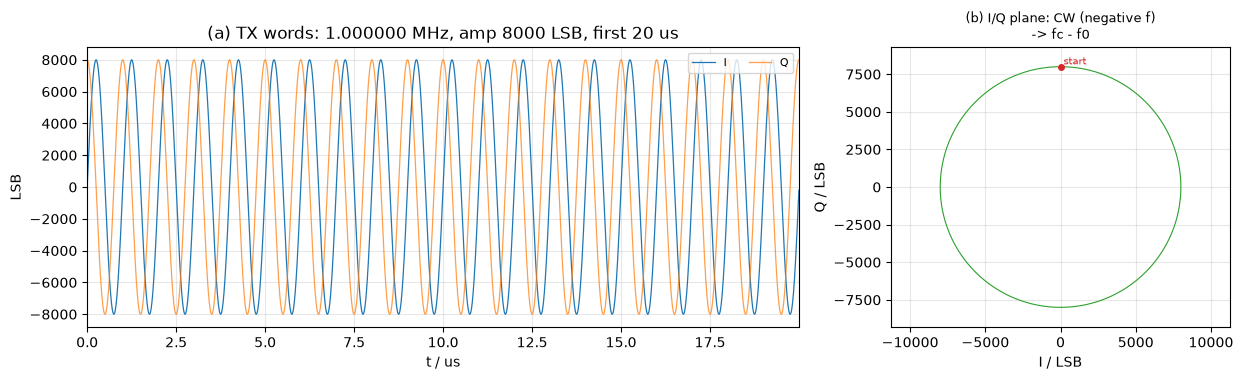

TX 波形：I 峰峰 16000 LSB，Q 峰峰 16000 LSB，幅度 -12.2 dBFS，周期 1.000 us，顺时针 → 射频在 fc-1.0 MHz


In [14]:
if len(words) >= 64:
    import matplotlib.pyplot as plt

    w = np.asarray(words, dtype=np.uint32)
    tx_i = (w & 0xFFFF).astype(np.uint16).view(np.int16).astype(np.float64)
    tx_q = (w >> 16).astype(np.uint16).view(np.int16).astype(np.float64)
    tx_iq = tx_i + 1j * tx_q

    V = min(len(tx_iq), int(round(20e-6 * FS_WORD)))     # 前 20 us
    t_us = np.arange(V) / FS_WORD * 1e6

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9),
                             gridspec_kw={"width_ratios": [2.1, 1.0]})

    # (a) 时域：I/Q 两条正弦
    ax = axes[0]
    ax.plot(t_us, tx_i[:V], lw=0.9, label="I")
    ax.plot(t_us, tx_q[:V], lw=0.9, alpha=0.75, label="Q")
    ax.set_xlim(0, t_us[-1])
    ax.set_xlabel("t / us")
    ax.set_ylabel("LSB")
    ax.set_title("(a) TX words: %.6f MHz, amp %d LSB, first %.0f us"
                 % (F0 / 1e6, AMP, t_us[-1]))
    ax.legend(loc="upper right", fontsize=8, ncol=2)
    ax.grid(alpha=0.3)

    # (b) I-Q 平面：一个周期（1 us），轨迹方向 = 边带方向
    n1 = min(len(tx_iq), int(round(FS_WORD / TONE_HZ)))
    ax = axes[1]
    ax.plot(tx_i[:n1], tx_q[:n1], lw=0.8, color="C2")
    ax.plot([tx_i[0]], [tx_q[0]], "o", ms=4, color="C3")
    ax.text(tx_i[0], tx_q[0], " start", fontsize=7, color="C3", va="bottom")
    if n1 > 2:
        dphi = np.angle(np.exp(1j * np.diff(np.angle(tx_iq[:n1]))))
        cw = float(np.median(dphi)) < 0.0
    else:
        cw = True
    ax.set_title("(b) I/Q plane: %s\n-> fc %s f0"
                 % ("CW (negative f)" if cw else "CCW (positive f)",
                    "-" if cw else "+"), fontsize=9)
    ax.set_xlabel("I / LSB")
    ax.set_ylabel("Q / LSB")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("TX 波形：I 峰峰 %d LSB，Q 峰峰 %d LSB，幅度 %.1f dBFS，"
          "周期 %.3f us，%s"
          % (int(np.ptp(tx_i[:V])), int(np.ptp(tx_q[:V])),
             20.0 * np.log10(AMP / 32768.0), 1e6 / TONE_HZ,
             "顺时针 → 射频在 fc-%.1f MHz" % (TONE_HZ / 1e6) if cw
             else "逆时针 → 射频在 fc+%.1f MHz" % (TONE_HZ / 1e6)))
else:
    print("TX 样点太少（%d 字），跳过波形" % len(words))


**应该看到**：左图两条正弦、周期 1 µs、峰峰各约 16 000 LSB（$2A$）；右图是一个漂亮的圆，起点标在顶部（$I≈0$、$Q≈A$），按标题给出的方向旋转。

**判读技巧与排错**

| 现象 | 含义 | 处置 |
| --- | --- | --- |
| `I[0]≈0、Q[0]=A` | 式(4-8) 正常 | 无 |
| `I[0]=A、Q[0]≈0` | I/Q 对调 | 也能工作，只是射频在另一侧边带 |
| 周期 ≠1 µs | `FS_WORD` 或 `TONE_HZ` 不对 | 回看 §3 的 256 MHz 字率 |
| 包络忽大忽小 | 帧长非整周期或幅度溢出 | 检查 `N_TX_WORDS` 是否为 256 倍数 |
| I-Q 轨迹不是圆 | 相位不是 90° | 检查打包位序 `{Q, I}` |
| 起点的方向与预期相反 | I/Q 定义相反 | 见 §5.3，判据取绝对值即可 |

### 5.5 放进 DDR：`allocate` 与 cache

PYNQ 的 `allocate()` 从 CMA 里申请**物理连续**内存，返回的 `device_address` 就是 DMA 要写的物理地址。CPU 写完必须 `flush()` 把 cache 刷回内存，否则 DMA 可能搬走旧数据。DMA 写完后再 `invalidate()` 才读得对。

本册在发送前做一次"写入 → flush → invalidate → 回读比对"，把 cache 问题一次性排除掉。

### 动手：申请缓冲区并验证


In [15]:
buf = allocate(shape=(N_TX_WORDS,), dtype=np.uint32)
buf[:] = words
buf.flush()
buf.invalidate()
got = np.asarray(buf, dtype=np.uint32).copy()
buf.flush()
same = bool(np.array_equal(got, words))

print("缓冲区 device_address=0x%08X  对齐=%d B  %d B"
      % (int(buf.device_address), int(buf.device_address) % 4096, buf.nbytes))

check("帧长在 DMA LENGTH 上限内", buf.nbytes <= LEN_MAX,
      "%d B / %d B" % (buf.nbytes, LEN_MAX),
      hint="确认 hwh 的 C_SG_LENGTH_WIDTH 与加载的位流一致")
check("DDR 回读与生成数据一致", same,
      "%d/%d 字相同" % (int(np.sum(got == words)), buf.size),
      hint="不一致 = flush 没生效，DMA 会搬走旧 cache")


缓冲区 device_address=0x21000000  对齐=0 B  16775168 B
  [PASS] 帧长在 DMA LENGTH 上限内                         16775168 B / 16777215 B
  [PASS] DDR 回读与生成数据一致                              4193792/4193792 字相同


True

## 6. 发送：用 AXI DMA 打一次长突发

### 6.1 单次突发，不做循环

v105 位流的 DMA 是简单模式（`C_INCLUDE_SG=0`）：一次 `LENGTH` 只搬一段，搬完就停，DAC 随之**冻结在最后一个字**上（输出直流）。要连续发射只能不断重装 `LENGTH`，那就是旧的 `TxLoop`。

验证链路并不需要连续发射：**把一段足够长的信号一次打出去，在它播出期间把接收窗口挂上去**，就一定能抓到。本册用 16 ms 突发、1.024 ms 接收窗，余量约 15 倍。少一个后台线程，也少一类"帧间空洞"的干扰，时序反而更确定。

### 6.2 寄存器地图（AXI DMA 简单模式）

| 方向 | 寄存器 | 偏移 | 本册用法 |
| --- | --- | --- | --- |
| MM2S（发） | `DMACR` | `0x00` | bit0=RS 启动，bit2=Reset，bit12=IOC 中断使能 |
| MM2S | `DMASR` | `0x04` | 状态；bit12=IOC 表示本帧完成 |
| MM2S | `SRCADDR` | `0x18` | 源物理地址（只写一次） |
| MM2S | `LENGTH` | `0x28` | **写这个寄存器就是启动一帧** |
| S2MM（收） | `DMACR` | `0x30` | 同上 |
| S2MM | `DMASR` | `0x34` | 同上 |
| S2MM | `DSTADDR` | `0x48` | 目的物理地址 |
| S2MM | `LENGTH` | `0x58` | 请求字节数；完成后回读为**实际搬入量** |

**最大的坑：IOC 是 bit12（`0x1000`），不是 bit4。** bit4 是 `DMAIntErr`。把 bit4 当完成位，会看到"一帧都没完成"或者永远在等。

`DMASR` 的 W1C 清标志掩码是 `0x73F0`（IOC + Dly + Err_Irq + 6 个错误原因位），写 1 清除。

### 动手：定义寄存器常量


In [16]:
MM2S_DMACR, MM2S_DMASR = 0x00, 0x04
MM2S_SRCADDR, MM2S_LENGTH = 0x18, 0x28

DMACR_RS = 1 << 0
DMACR_RESET = 1 << 2
DMACR_IOC_EN = 1 << 12

SR_HALTED = 1 << 0
SR_IDLE = 1 << 1
SR_IOC = 1 << 12
SR_ERR_IRQ = 1 << 14
SR_ERR = (1 << 4) | (1 << 5) | (1 << 6) | (1 << 7) | (1 << 8) | (1 << 9) | SR_ERR_IRQ
SR_W1C = 0x73F0          # IOC | Dly | Err_Irq + 6 个错误原因位


### 6.3 一个最小的 DMA 封装

简单模式（`C_INCLUDE_SG=0`）没有描述符链，四个寄存器就够：复位、启动、下发地址与长度、读状态。`decode()` 把 `DMASR` 翻成人话，出问题时先看它。

### 动手：`DmaSimple`


In [17]:
class DmaSimple(object):
    """AXI DMA 单通道（简单模式）。direction: 'mm2s' 或 's2mm'。"""

    def __init__(self, base, direction, name=""):
        self.name = name or direction.upper()
        self.direction = direction
        self.mmio = MMIO(base, 0x10000)
        if direction == "mm2s":
            self.r_cr, self.r_sr, self.r_addr, self.r_len = 0x00, 0x04, 0x18, 0x28
        else:
            self.r_cr, self.r_sr, self.r_addr, self.r_len = 0x30, 0x34, 0x48, 0x58

    def sr(self):
        return self.mmio.read(self.r_sr) & 0xFFFFFFFF

    def decode(self, v=None):
        v = self.sr() if v is None else v
        bits = ((0, "Halted"), (1, "Idle"), (4, "DMAIntErr"), (5, "DMASlvErr"),
                (6, "DMADecErr"), (7, "SGIntErr"), (8, "SGSlvErr"), (9, "SGDecErr"),
                (12, "IOC"), (13, "Dly"), (14, "Err"))
        on = [n for b, n in bits if v & (1 << b)]
        return ", ".join(on) if on else "(全 0)"

    def reset(self, timeout=0.5):
        self.mmio.write(self.r_cr, DMACR_RESET)
        t0 = time.time()
        while time.time() - t0 < timeout:
            if self.sr() & SR_HALTED:
                break
            time.sleep(0.002)
        self.mmio.write(self.r_sr, SR_W1C)
        return self

    def start_channel(self):
        self.mmio.write(self.r_sr, SR_W1C)
        self.mmio.write(self.r_cr, DMACR_RS | DMACR_IOC_EN)
        return self

    def kick(self, phys_addr, nbytes):
        if nbytes > LEN_MAX:
            raise ValueError("%d B 超过 LENGTH 上限 %d B" % (nbytes, LEN_MAX))
        self.mmio.write(self.r_addr, phys_addr & 0xFFFFFFFF)
        self.mmio.write(self.r_len, nbytes & 0xFFFFFFFF)

    def clear_sr(self):
        self.mmio.write(self.r_sr, SR_W1C)

    def stop(self):
        self.mmio.write(self.r_cr, 0)


### 6.4 单次发射 + 立刻接收的时序

简单模式没有描述符链，也没有"硬件自动重装"。所以本册改成**一次长突发**：

```
时间轴（按本册参数）：

TX   |==== 16.382 ms 单次突发 ============================|
RX      |==== 16.383 ms 整包抓取 ==========================|  (启动间隔 ≈ 几十 us)
        ^ 写 S2MM.LENGTH 的时刻
```

三条设计规则：

1. **只写一次 `LENGTH`**：写第二次才会搬第二帧，本册不写 —— 一帧就是一次突发。
2. **接收侧提前就位**：先把 RX 缓冲区申请好、`RS=1`、目的地址写好，只差最后一个 `LENGTH`。把"申请内存 + 复位 + 启动通道"这些耗时动作挪到 TX 之前，启动间隔才能压到几十 µs。
3. **TX 启动与 RX 启动放在同一格**：两格之间的人工停顿可能远超 16 ms，突发早播完了。这也是本册把"发送 + 接收"合成一格的原因。

为什么突发要长：本册的接收窗**等于一整包**（16.383 ms），所以突发也必须贴近上限（4 193 792 字 = 16.382 ms）。突发几乎没有余量，启动间隔那几十 µs 会落在窗口尾部，那一段 DAC 已经冻结、采到的是直流 —— 这是整包请求的代价。收益是：S2MM 在 `tlast` 处结束，起点和终点都在包边界上，见 §7.1。


In [18]:
def tx_once(dma, buf):
    """单次发射：复位 → RS=1 → 写源地址 → 写 LENGTH（这一步开始搬数）。"""
    dma.reset()
    dma.start_channel()
    dma.mmio.write(MM2S_SRCADDR, int(buf.device_address))
    dma.mmio.write(MM2S_LENGTH, int(buf.nbytes))
    return time.time()


def tx_wait(dma, timeout):
    """等本次突发搬完（IOC）或报错，返回 (完成?, DMASR, 用时 s)。"""
    t0 = time.time()
    while time.time() - t0 < timeout:
        sr = dma.sr()
        if sr & SR_ERR:
            return False, sr, time.time() - t0
        if sr & SR_IOC:
            return True, sr, time.time() - t0
    return False, dma.sr(), time.time() - t0


### 6.5 动手：检查单次发射的前置条件

这一格**不发射**：它只建好 `TX` 对象、确认寄存器可读、确认突发长度没超过 `LENGTH` 上限。真正的发射在 §7 与接收放在同一格里做。

| 检查 | 期望 |
| --- | --- |
| `DMASR ≠ 0xFFFFFFFF` | DMA 在总线上 |
| `buf.nbytes ≤ LEN_MAX` | 16 775 168 B ≤ 16 777 215 B |
| 突发长度 ≈ 接收窗口 | 16.382 ms vs 16.383 ms（整包） |


In [19]:
TX = DmaSimple(DMA_TX_BASE, "mm2s", "TX(MM2S)")
check("TX DMASR 可读（≠0xFFFFFFFF）", TX.sr() != 0xFFFFFFFF, "0x%08X" % TX.sr(),
      hint="打到空地址：位流没加载 / DMA 基地址不对")
check("突发长度在 DMA LENGTH 上限内", buf.nbytes <= LEN_MAX,
      "%d B / %d B" % (buf.nbytes, LEN_MAX),
      hint="TX_FRAME_US 太大：24 bit LENGTH 最多 16 777 215 B")

print("本次突发 %.3f ms（%d 字 / %d B），DMA 单次上限 %.3f ms"
      % (FRAME_MS, buf.size, buf.nbytes, LEN_MAX / WORD_BYTES / FS_WORD * 1e3))


  [PASS] TX DMASR 可读（≠0xFFFFFFFF）                   0x00000001
  [PASS] 突发长度在 DMA LENGTH 上限内                       16775168 B / 16777215 B
本次突发 16.382 ms（4193792 字 / 16775168 B），DMA 单次上限 16.384 ms


**应该看到**：两条 `[PASS]`，一行 `本次突发 16.382 ms（4193792 字 / 16775168 B）`。

**如果不对**：`buf.nbytes > LEN_MAX` → 调小 `TX_FRAME_US` 后重跑 §5（重新造数），或改位流为 SG 模式。

**DMASR 位判读（接收完成后同用这张表）**

| `DMASR` 位 | 现象 | 处置 |
| --- | --- | --- |
| `IOC`（bit12） | 正常完成 | 无 |
| `DMAIntErr`（bit4） | 长度不是 4 的倍数 / 传输中断 | 检查 `LENGTH` 计算 |
| `DMASlvErr`（bit5） | 源地址非法 | 缓冲区是否 `freebuffer()` 后又发 |
| `DMADecErr`（bit6） | 地址映射错 | 位流/hwh 不同源 |
| `Err`（bit14） | 内部错误 | 复位 DMA，重跑本节 |
| 全 1 | 地址打空 | 检查基地址与位流 |


## 7. 接收：在一次突发里抓一帧回波

### 7.1 为什么接收侧有"单包上限"

ADC 数据先经自定义 IP `adc2axis_0` 打包成 AXI-Stream。它在每 `C_FRAME_LEN` 个字后拉一次 `tlast`。S2MM 在简单模式下遇到 `tlast` 就结束当前包（或请求长度到了就结束）。

| 位流版本 | `C_FRAME_LEN` | 单包时长 | 本册请求 |
| --- | --- | --- | --- |
| v105 | 4 194 303 | 16.383 ms | 4 194 303 字（1 整包，16.383 ms） |
| 旧版 | 16 384 | 64 µs | 16 384 字（64 µs） |

**本册改成"整包请求"**：请求长度正好等于 `C_FRAME_LEN`，S2MM 不会在一个包的中间停下，而是在 `tlast` 处结束。这样每次抓取的起点和终点都落在包边界上，`adc2axis_0` 的帧计数不会停在半路，下一次抓取从帧首开始 —— 也就不会长期停在"半个包"的背压状态里。

一个必然的副作用：`adc2axis_0` 的帧计数**不随 DMA 复位清零**，只随被接收的字前进。所以**第一次**整包抓取可能落在半路，在第一个 `tlast` 就提前结束（只收到 `k` 字，`k < C_FRAME_LEN`）；这一包结束后计数归零，**之后每次都是完整的一包**。§7.4 用一次"预热抓取"把这个随机性提前消耗掉。

请求长度受 24 bit `LENGTH` 约束：4 194 303 字 = 16 777 212 B ≤ 16 777 215 B，正好卡在上限内。

### 7.2 哨兵值：精确数出"搬了多少"

申请缓冲区后，用 `0xDEADBEEF` 预填再 `flush()`。DMA 只覆盖它真正写到的部分，回来后数"不等于哨兵的字数"就是真实搬入量。比依赖 `LENGTH` 回读更直观，也能立刻发现"只搬了 0 个字"。

### 7.3 数据布局

RX 侧一个字同样是 `{Q, I}`，所以解包是

$$ x_n=I_n+jQ_n=\big(w_n\ \&\ 0xFFFF\big)+j\big(w_n\gg16\big) \tag{4-9} $$

**说明** 16 位是无符号存储、有符号解释（`.view(np.int16)`），漏掉这一步会把 −1 读成 65535，波形会出现巨大跳变。



### 7.4 与突发对齐的一次抓取

一次抓取分五步，**全部在同一格里**：

| 步 | 动作 | 耗时量级 |
| --- | --- | --- |
| ⓪ | 预热抓取一整包（丢弃），只为让 `adc2axis_0` 的帧计数归零 | ≈17 ms |
| ① | 申请 RX 缓冲区、预填哨兵、`RS=1`、写目的地址 | ms（放到 TX 之前） |
| ② | `tx_once()`：写 `MM2S.LENGTH` 启动 16.382 ms 突发 | µs |
| ③ | 写 `S2MM.LENGTH` 启动接收 | µs |
| ④ | 轮询 S2MM 的 `IOC`，读回搬入量并解包 | 16.4 ms |
| ⑤ | 等 TX 的 `IOC`，确认整帧发完 | ≈16 ms |

②③之间就是"启动间隔"，正常在几十 µs 量级。整包窗口 16.383 ms 与突发 16.382 ms 等长，间隔会让窗口末端超出突发几十 µs —— 那一段 DAC 已冻结，采到的是直流，属预期；分析窗口只取前 1 ms（§8），不受影响。

### 动手：接收工具函数

这一格只定义，不发请求。


In [20]:
RX = DmaSimple(DMA_RX_BASE, "s2mm", "RX(S2MM)")
SENT = np.uint32(0xDEADBEEF)

if RX_FULL_FRAME and int(C_FRAME_LEN) <= MAX_WORDS:
    REQ_WORDS = int(C_FRAME_LEN)         # 整包：S2MM 在 tlast 处自然结束
else:
    REQ_WORDS = min(262144, int(C_FRAME_LEN), MAX_WORDS)
    REQ_WORDS = max(4, (REQ_WORDS // 4) * 4)

REQ_BYTES = REQ_WORDS * WORD_BYTES
REQ_US = REQ_WORDS / FS_WORD * 1e6

print("RX 请求 %d 字 = %.3f ms（%d B，LENGTH 上限 %d B）%s"
      % (REQ_WORDS, REQ_US / 1e3, REQ_BYTES, LEN_MAX,
         "  ← 整包，tlast 对齐" if REQ_WORDS == int(C_FRAME_LEN) else ""))
print("每次申请 %.2f MB；接收窗 %.3f ms vs 突发 %.3f ms，"
      "末尾约 %.0f us 落在突发外（DAC 已冻结，是直流）"
      % (REQ_BYTES / 1e6, REQ_US / 1e3, FRAME_MS, REQ_US / 1e3 - FRAME_MS))


def rx_alloc(n_words):
    """申请接收缓冲区并预填哨兵，flush 后 DMA 才能安全写入。"""
    b = allocate(shape=(n_words,), dtype=np.uint32)
    b[:] = SENT
    b.flush()
    return b


def rx_arm(b):
    """接收侧就位：复位、RS=1、写目的地址；还没有 LENGTH，不会搬数。"""
    RX.stop()
    RX.reset()
    RX.mmio.write(RX.r_addr, int(b.device_address))
    RX.start_channel()


def rx_finish(b, timeout=1.0, keep=False, unpack=True):
    """等 S2MM 的 IOC，读回实际搬入量，解包成复数样点。

    keep=False 立即释放缓冲区；keep=True 保留（buf），供 §7.6/7.7 复核。
    unpack=False 只数搬入量、不解包（预热抓取用，省内存与时间）。
    """
    t0 = time.time()
    sr, ok = 0, False
    while time.time() - t0 < timeout:
        sr = RX.sr()
        if sr & SR_IOC:
            ok = True
            break
        if (sr & SR_HALTED) and not (sr & SR_IDLE):
            break
        time.sleep(0.00005)
    dt = time.time() - t0
    nbytes = RX.mmio.read(0x58) & 0xFFFFFFFF     # 完成后回读 = 实际搬运量
    RX.clear_sr()
    b.invalidate()
    w = np.asarray(b, dtype=np.uint32).copy()
    if not keep:
        b.freebuffer()
    n_real = int(np.count_nonzero(w != SENT))
    if unpack:
        lo = (w[:n_real] & 0xFFFF).astype(np.uint16).view(np.int16).astype(np.float64)
        hi = (w[:n_real] >> 16).astype(np.uint16).view(np.int16).astype(np.float64)
        xv = lo + 1j * hi
    else:
        xv = np.zeros(0, dtype=np.complex128)
    out = {"x": xv, "w": w, "sr": sr, "ok": ok, "n": n_real,
           "dt": dt, "nbytes": nbytes}
    if keep:
        out["buf"] = b
    return out


RX 请求 4194303 字 = 16.384 ms（16777212 B，LENGTH 上限 16777215 B）  ← 整包，tlast 对齐
每次申请 16.78 MB；接收窗 16.384 ms vs 突发 16.382 ms，末尾约 0 us 落在突发外（DAC 已冻结，是直流）


### 动手：发一次 + 立刻收

这一格把"启动 TX → 启动 RX → 等 RX → 等 TX"串在一起，请**整格运行**，不要拆开。


In [21]:
# ⓪ 预热：整包抓一次就丢掉。目的只有一个——把 adc2axis_0 的帧计数跑到 0，
#    这样下面这一包一定从帧首开始。抓到的内容与本次信号无关，不参与分析。
if RX_FULL_FRAME:
    WB = rx_alloc(REQ_WORDS)
    rx_arm(WB)
    RX.mmio.write(RX.r_len, REQ_BYTES)
    W = rx_finish(WB, unpack=False)
    print("预热抓取：%d / %d 字（%s），帧计数已归零"
          % (W["n"], REQ_WORDS,
             "整包" if W["n"] >= 0.999 * REQ_WORDS else "在 tlast 处提前结束"))
    del W, WB
else:
    print("跳过预热（RX_FULL_FRAME=False）")

# ① 接收侧先就位（申请内存 + RS=1 + 目的地址），把耗时动作挪到突发之前
RXB = rx_alloc(REQ_WORDS)
rx_arm(RXB)

# ② 启动单次突发
t_tx = tx_once(TX, buf)

# ③ 立刻启动接收（整包，S2MM 在 tlast 处结束）
RX.mmio.write(RX.r_len, REQ_BYTES)
t_rx = time.time()

GAP_US = (t_rx - t_tx) * 1e6
print("TX 启动 → RX 启动：%.1f us（突发 %.3f ms，接收窗 %.3f ms）"
      % (GAP_US, FRAME_MS, REQ_US / 1e3))

# ④ 等接收完成
G = rx_finish(RXB)
x = G["x"]
n_real = G["n"]
print("RX 实收 %d 字 = %.3f ms（墙钟 %.2f ms）  DMASR=0x%08X  %s"
      % (n_real, n_real / FS_WORD * 1e3, G["dt"] * 1e3, G["sr"], RX.decode(G["sr"])))
print("  与整包差 %+d 字（%+.3f ms）：%s"
      % (n_real - REQ_WORDS, (n_real - REQ_WORDS) / FS_WORD * 1e3,
         "在 tlast 处结束" if n_real < REQ_WORDS else "按 LENGTH 结束"))
TAIL_MS = (GAP_US * 1e-3 + n_real / FS_WORD * 1e3) - FRAME_MS

# 实测包长：LENGTH 用尽且报 DMAIntErr(bit4) = 停在中途，真实包比请求更长
LEN_CUT = (n_real >= REQ_WORDS) and bool(G["sr"] & (1 << 4))
if LEN_CUT:
    print("  ⚠ LENGTH 用尽且带 DMAIntErr：实际包长 > %d 字，§3.2 的 C_FRAME_LEN 不对"
          % REQ_WORDS)
elif n_real < 0.99 * REQ_WORDS:
    print("  实测包长 ≈ %d 字 = %.3f ms（§3.2 写的是 %d 字）"
          % (n_real, n_real / FS_WORD * 1e3, int(C_FRAME_LEN)))

# ⑤ 等整帧发完（突发余下部分仍在播）
tx_ok, tx_sr, tx_dt = tx_wait(TX, FRAME_MS * 1e-3 + 0.05)
print("TX 突发：%s，DMASR=0x%08X，从启动到 IOC %.2f ms"
      % ("完成(IOC)" if tx_ok else "未完成", tx_sr, tx_dt * 1e3))

check("TX→RX 启动间隔 < 1 ms", GAP_US < 1000.0, "%.1f us" % GAP_US,
      hint="间隔过大：内存必须提前申请，rx_arm 里只做复位+RS+地址")
check("S2MM 收到 IOC", G["ok"], "DMASR=0x%08X" % G["sr"],
      hint="没 IOC：RX 侧没数据 / 基地址不对；请求短于 C_FRAME_LEN 时带错误位属正常")
check("RX 实收 = 请求长度（>= 99.9%）", n_real >= 0.999 * REQ_WORDS,
      "%d / %d 字" % (n_real, REQ_WORDS),
      hint="明显短于请求：预热没做 / 帧计数没归零；或真实包长比 C_FRAME_LEN 小（见上行实测）")
check("整包在 tlast 处结束（不是按 LENGTH 截断）", not LEN_CUT,
      ("按 LENGTH 截断：实际包长 > %d 字" % REQ_WORDS) if LEN_CUT
      else "tlast 结束，差 %+d 字" % (n_real - REQ_WORDS),
      hint="把 §3.2 的 CFL_FALLBACK 改成实测包长后，重跑 §3.2~§7.4")
check("接收窗与突发对齐（尾部溢出 < 0.5 ms）", TAIL_MS <= 0.5,
      "尾部 %+.3f ms" % TAIL_MS,
      hint="窗口比突发长：调大 TX_FRAME_US（上限约 16.382 ms）后重跑 §5")
check("TX 突发完成（IOC）", tx_ok, "DMASR=0x%08X" % tx_sr,
      hint="突发没发完：检查 DMASR 错误位，或把 tx_wait 的超时调大")
uniq_real = len(np.unique(np.asarray(x.real[:20000], dtype=np.int16))) if n_real else 0
check("RX 不是恒定值（数据在变）", uniq_real > 8, "I 唯一值 %d" % uniq_real,
      hint="全同一个值 = S2MM 没真正搬 / ADC 没有数据流")


预热抓取：4194299 / 4194303 字（整包），帧计数已归零
TX 启动 → RX 启动：371.5 us（突发 16.382 ms，接收窗 16.384 ms）
RX 实收 4194299 字 = 16.384 ms（墙钟 15.57 ms）  DMASR=0x00001002  Idle, IOC
  与整包差 -4 字（-0.000 ms）：在 tlast 处结束
TX 突发：完成(IOC)，DMASR=0x00001002，从启动到 IOC 0.04 ms
  [PASS] TX→RX 启动间隔 < 1 ms                          371.5 us
  [PASS] S2MM 收到 IOC                                DMASR=0x00001002
  [PASS] RX 实收 = 请求长度（>= 99.9%）                     4194299 / 4194303 字
  [PASS] 整包在 tlast 处结束（不是按 LENGTH 截断）               tlast 结束，差 -4 字
  [PASS] 接收窗与突发对齐（尾部溢出 < 0.5 ms）                    尾部 +0.373 ms
  [PASS] TX 突发完成（IOC）                               DMASR=0x00001002
  [PASS] RX 不是恒定值（数据在变）                             I 唯一值 4447


True

**应该看到**：`预热抓取：… 字`，`TX 启动 → RX 启动：xx us`（几十 µs），`RX 实收 4194303 字 = 16.383 ms`，`与整包差 -N 字（在 tlast 处结束）`，`TX 突发：完成(IOC)`。

`DMASR` 常带 `DMAIntErr`：整包在 `tlast` 处提前一点结束、`LENGTH` 没用完，**这是本册预期行为**，只认 `IOC` 与实际搬入量。如果 `与整包差` 是负的几十个字，就是帧计数回零后 DMA 又多吃了几拍，正常。

**如果不对**

| 现象 | 含义 | 处置 |
| --- | --- | --- |
| 启动间隔 > 1 ms | `rx_arm` 里做了耗时动作 | 内存提前申请；`rx_arm` 只做复位+RS+地址 |
| 无 IOC，`Halted=1` | `RS` 没置上 | 重跑本节（`rx_arm` 内含 reset） |
| `n_real=0` | 哨兵一个没动 | 基地址错 / `adc2axis` 没出数 |
| `n_real` 远小于整包 | 帧计数没归零，落在半路 | 确认预热格已跑；或重跑本节 |
| `n_real` 恰为 16 384（旧位流） | 位流 `C_FRAME_LEN` 是旧值 | 正常；把 `CFL_FALLBACK` 改成 16384 后重跑 |
| 带 `⚠ LENGTH 用尽且带 DMAIntErr` | 实际包长 > 请求长度 | §3.2 的 `C_FRAME_LEN` 偏小：按实测值改 `CFL_FALLBACK` |
| 「尾部溢出 < 0.5 ms」FAIL | 启动间隔过大或窗口比突发长 | 压缩 `rx_arm` 耗时；调大 `TX_FRAME_US` 重跑 §5 |
| TX 无 IOC | 突发没发完/超时 | 看 DMASR 错误位；复位 DMA |


### 7.5 先画波形，再做分析

抓回来的数据先别急着做 FFT。**时域波形是第一手证据**，一张图就能回答四件事：

1. **有没有**：波形在动，还是接近一条直线；
2. **是不是正弦**：I/Q 各应是 1 MHz 正弦，周期 1 µs；
3. **有没有削顶**：幅度碰到 ±32767 说明 ADC 饱和，后面的 SNR/镜像都不作数；
4. **有没有断流**：按 4 µs 一块算 AC RMS，若中间掉到 50 LSB 以下，说明 DAC 帧间有空洞（§6 的实验）。

只有这四条都过了，§8 的频谱数字才有意义 —— 频谱会把断流和削顶"平均"掉，反而看不出问题。

### 动手：波形速览


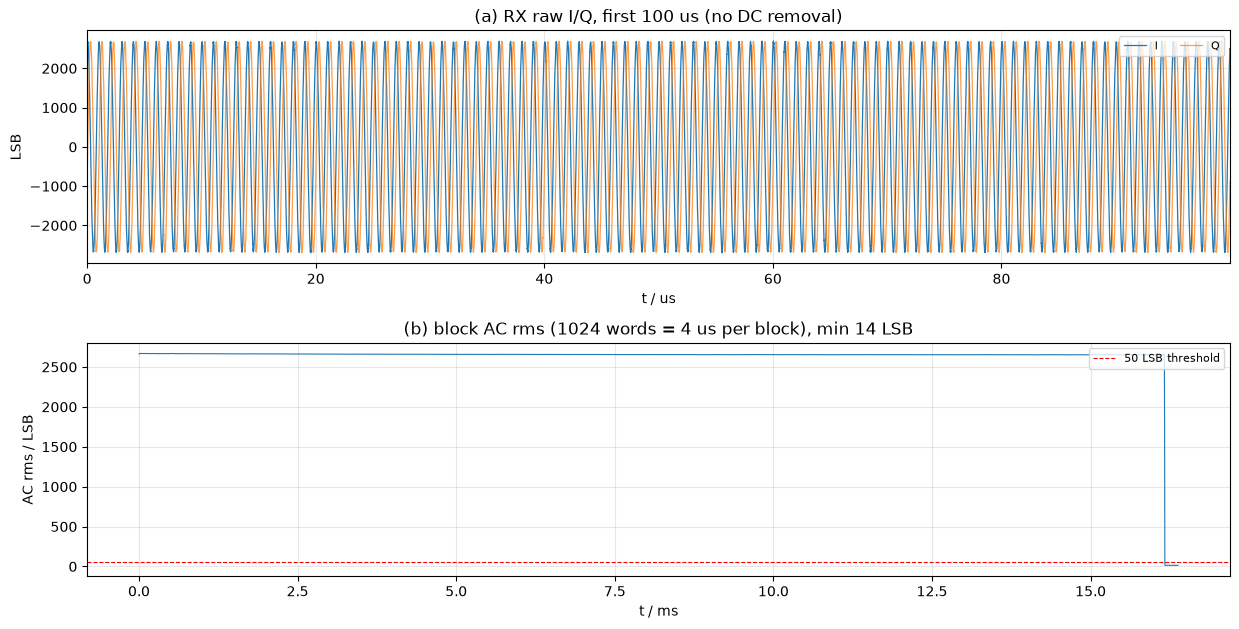

波形速览：I 峰峰 5396 LSB，直流 +33.4 -12.1j LSB，削顶点 0，块 rms 中位 2655 LSB（最低 14）
  看周期：1 MHz → 1 us 一个正弦；看圆心：直流偏移就是本振泄漏/失调。


In [22]:
if n_real >= 64:
    import matplotlib.pyplot as plt

    # (a) 前 20 us 原始 I/Q（不去直流，就是要看圆心偏移）
    V = min(n_real, int(round(100e-6 * FS_WORD)))
    t_us = np.arange(V) / FS_WORD * 1e6

    # (b) 每 1024 字（4 us）一块的 AC RMS，看有没有断流 / 冻结
    PW = 1024
    nb = n_real // PW
    if nb == 0:
        PW = n_real
        nb = 1
    xb = x[:nb * PW].reshape(nb, PW)
    blk_rms = np.sqrt(np.mean(np.abs(xb - xb.mean(axis=1, keepdims=True)) ** 2, axis=1))
    tb_ms = (np.arange(nb) + 0.5) * PW / FS_WORD * 1e3

    fig, axes = plt.subplots(2, 1, figsize=(12.5, 6.4),
                             gridspec_kw={"height_ratios": [1.0, 1.0]})
    fig.subplots_adjust(hspace=0.55)

    ax = axes[0]
    ax.plot(t_us, x.real[:V], lw=0.9, label="I")
    ax.plot(t_us, x.imag[:V], lw=0.9, alpha=0.75, label="Q")
    ax.set_xlim(0, t_us[-1])
    ax.set_xlabel("t / us")
    ax.set_ylabel("LSB")
    ax.set_title("(a) RX raw I/Q, first %.0f us (no DC removal)" % t_us[-1])
    ax.legend(loc="upper right", fontsize=8, ncol=2)
    ax.grid(alpha=0.3)

    ax = axes[1]
    ax.plot(tb_ms, blk_rms, lw=0.8)
    ax.axhline(50.0, color="r", ls="--", lw=0.8, label="50 LSB threshold")
    ax.set_xlabel("t / ms")
    ax.set_ylabel("AC rms / LSB")
    ax.set_title("(b) block AC rms (1024 words = 4 us per block), min %.0f LSB"
                 % float(blk_rms.min()))
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    p2p_i = float(np.ptp(x.real[:V]))
    clip = int(np.sum(np.abs(x.real[:V]) >= 32760)
               + np.sum(np.abs(x.imag[:V]) >= 32760))
    print("波形速览：I 峰峰 %.0f LSB，直流 %+.1f %+.1fj LSB，削顶点 %d，"
          "块 rms 中位 %.0f LSB（最低 %.0f）"
          % (p2p_i, x.real.mean(), x.imag.mean(), clip,
             float(np.median(blk_rms)), float(blk_rms.min())))
    print("  看周期：1 MHz → 1 us 一个正弦；看圆心：直流偏移就是本振泄漏/失调。")
else:
    print("RX 只有 %d 字，跳过波形预览" % n_real)


**应该看到**

- **(a)** I/Q 两条正弦，周期 1 µs，**围绕 0 上下摆动**（或有几十~几百 LSB 的固定偏移）。峰峰约为 `2 × AC_rms × 1.4`，如果肉眼看到"平顶"，就是削顶；
- **(b)** 一条几乎水平的线（各块 RMS 接近），且远高于 50 LSB 阈值。线在中间掉下去 = TX 有空洞或停发；整条贴地 = 没有回波。

**判读表**

| 波形现象 | 结论 | 下一步 |
| --- | --- | --- |
| I/Q 正弦清晰、周期 1 µs | 收发链路通 | 进 §8 看频谱、SNR、镜像 |
| 平顶 / 峰峰贴 ±32767 | ADC 饱和 | 加大衰减器或降 `AMP` |
| 波形很密、周期 ≈0.2 µs | 频率不是 1 MHz | 检查 `TONE_HZ` 与 NCO |
| 一条直线 + 小噪声 | 没收到信号 | 查外部环回；用频谱仪看 TX 口 |
| (b) 中间掉到阈值以下 | 突发提前结束 / 停发 | 查 §7 的 `tx_wait` 是否收到 IOC |
| (a) 有固定直流偏移 | 本振泄漏 + ADC 失调 | 正常物理现象，分析时去均值 |


### 7.6 诊断：前 20 µs 原始数据与"保持段"

"保持段"= 连续的若干个字**完全相同**。AXI-Stream 上 `tdata` 保持不动的来源只有三类：

| 来源 | 特征 | 物理含义 |
| --- | --- | --- |
| DMA 没写这段 | 值 = 哨兵 `0xDEADBEEF`，或上一次抓取的旧内容 | 传输提前结束（`tlast` / 长度 / `DMASR` 错误位） |
| ADC 侧没有新样点 | 值 = ADC 最后输出的码，位置任意 | `adc2axis` 停更：时钟/SYSREF 掉了，或 `tready` 长期背压 |
| CPU 读到旧 cache | 值 = 缓冲区旧内容，长度是 64 B（16 字）的整数倍，起点对齐 | 少了 `invalidate()` |

判断顺序：**先看是不是哨兵 → 再看 16 字对齐 → 最后看两次抓取是否在同一位置复现**。下一格把前 20 µs 的字直接打出来并做游程统计。

### 动手：原始字与游程


In [23]:
if n_real >= 64:
    w = np.asarray(G["w"], dtype=np.uint32)
    V = min(n_real, int(round(20e-6 * FS_WORD)))

    print("前 20 us = %d 字（0 ~ %.2f us）" % (V, V / FS_WORD * 1e6))
    print("前 32 个字：")
    for r in range(0, min(V, 32), 8):
        print("  [%4d]  " % r + "  ".join("%08X" % int(v) for v in w[r:r + 8]))

    sent = int(np.sum(w[:V] == SENT))
    print("哨兵字数 %d / %d；不同值 %d 个"
          % (sent, V, len(np.unique(w[:V]))))

    # 游程：连续相同值的长度与起点
    d = np.diff(w[:V].astype(np.int64))
    starts = np.flatnonzero(np.r_[True, d != 0])
    ends = np.r_[starts[1:], V]
    lens = ends - starts
    j = int(np.argmax(lens))
    s0, l0, v0 = int(starts[j]), int(lens[j]), int(w[starts[j]])

    print("最长保持段：%d 字 = %.2f us，起点 %.2f us，值 0x%08X%s"
          % (l0, l0 / FS_WORD * 1e6, s0 / FS_WORD * 1e6, v0,
             "（哨兵：DMA 没写）" if v0 == int(SENT) else ""))
    print("  起点 mod 16 = %d，长度 mod 16 = %d（缓存行 = 16 字 = 64 B）"
          % (s0 % 16, l0 % 16))

    for tag, mn in ((">=2 字", 2), (">=16 字", 16), (">=256 字", 256)):
        m = lens >= mn
        print("  保持段 %-8s：%d 段，占 %.2f%%"
              % (tag, int(m.sum()), 100.0 * float(lens[m].sum()) / V))

    if l0 >= 8:
        for tag, c in (("起点", s0), ("终点", s0 + l0)):
            a, b = max(0, c - 16), min(V, c + 16)
            print("  保持段%s前后原始字：" % tag)
            for r in range(a, b, 8):
                print("    [%4d]  " % r
                      + "  ".join("%08X" % int(v) for v in w[r:r + 8]))
else:
    print("RX 只有 %d 字，跳过原始数据诊断" % n_real)


前 20 us = 5120 字（0 ~ 20.00 us）
前 32 个字：
  [   0]  000E0007  FFFFFFF3  0002FFEC  00020000  FDC80A2B  FE220A4F  FE540A49  FE8B0A58
  [   8]  FEBF0A74  FF2B0A64  FF630A79  FFB20A60  FFD10A6C  001A0A59  00720A69  00BA0A69
  [  16]  00FC0A69  012E0A71  015A0A53  019C0A4A  01EC0A3F  02430A3A  02660A2C  029F0A12
  [  24]  02EE0A09  033409DA  036509D3  039B09CD  03F109C2  0426098B  0457096D  0494094C
哨兵字数 0 / 5120；不同值 5093 个
最长保持段：1 字 = 0.00 us，起点 0.00 us，值 0x000E0007
  起点 mod 16 = 0，长度 mod 16 = 1（缓存行 = 16 字 = 64 B）
  保持段 >=2 字   ：0 段，占 0.00%
  保持段 >=16 字  ：0 段，占 0.00%
  保持段 >=256 字 ：0 段，占 0.00%


**怎么读这一格**

| 观察 | 结论 | 下一步 |
| --- | --- | --- |
| 保持段的值 = `DEADBEEF` | DMA 没写这段 | 看 `DMASR` 与 `nbytes`；检查 `tlast`/请求长度 |
| 保持段起点/长度都是 16 的倍数，值像是上一轮内容 | 缓存行问题 | 确认 `invalidate()` 在读取之前；不要复用未失效的 buffer |
| 保持段值 = 某个 ADC 码，位置不对齐，且**每次同一位置** | ADC/`adc2axis` 停更（确定性） | 查 LMK SYSREF、ADC tile、`tready` 背压 |
| 保持段位置**每次不同** | 偶发：时序/背压/抓取窗口撞上边界 | 加大突发长度，开抓前 `RX.reset()`，见下一格 |
| 保持段只在最前面几十个字 | AXI-Stream 流水线预热 | 一般可忽略（分析时跳过开头） |

### 7.7 重复抓取：区分"确定性停更"与"偶发掉数"

再抓一次同样的帧，比较两次的保持段位置：

- **位置完全一致** → 确定性：IP 停更、缓存对齐、或传输在固定长度处结束；
- **位置不一致 / 第二次没有** → 偶发：抓取与突发边界撞上、上一次传输的背压未消化。

同时做一次**缓存复核**：保留缓冲区，失效后连读两次，确认内存内容在传输结束后不再变化。

### 动手：重复抓取对比


In [24]:
DO_REPEAT = True


def hold_runs(v, minlen=8):
    d = np.diff(np.asarray(v, dtype=np.int64))
    st = np.flatnonzero(np.r_[True, d != 0])
    en = np.r_[st[1:], len(v)]
    ln = en - st
    m = ln >= minlen
    return st[m], ln[m]


if DO_REPEAT and n_real >= 64:
    b2 = rx_alloc(REQ_WORDS)
    rx_arm(b2)
    tx_once(TX, buf)
    RX.mmio.write(RX.r_len, REQ_BYTES)
    G2 = rx_finish(b2, keep=True)
    w2 = np.asarray(G2["w"], dtype=np.uint32)
    n2 = G2["n"]

    s1, l1 = hold_runs(np.asarray(G["w"], dtype=np.uint32)[:n_real])
    s2, l2 = hold_runs(w2[:n2])
    print("第一次：%d 段保持（>=8 字），最长 %d 字"
          % (len(s1), int(l1.max()) if len(l1) else 0))
    print("第二次：%d 段保持（>=8 字），最长 %d 字；实收 %d / %d 字"
          % (len(s2), int(l2.max()) if len(l2) else 0, n2, REQ_WORDS))
    same_pos = (len(s1) == len(s2)) and bool(np.array_equal(s1, s2))
    print("两次保持段起点完全一致：%s" % same_pos)

    bb = G2["buf"]
    a1 = np.asarray(bb, dtype=np.uint32).copy()
    bb.invalidate()
    a2 = np.asarray(bb, dtype=np.uint32).copy()
    bb.invalidate()
    a3 = np.asarray(bb, dtype=np.uint32).copy()
    print("缓存复核：失效后两次读一致 = %s；与失效前一致 = %s"
          % (bool(np.array_equal(a2, a3)), bool(np.array_equal(a1, a2))))
    bb.freebuffer()

    check("重复抓取：保持段位置可复现", same_pos, "一致=%s" % same_pos,
          hint="不可复现 = 偶发（时序/背压）；可复现 = 确定性（IP 停更或缓存对齐）")
else:
    print("跳过重复抓取（DO_REPEAT=False 或 RX 数据不足）")


第一次：0 段保持（>=8 字），最长 0 字
第二次：0 段保持（>=8 字），最长 0 字；实收 4194299 / 4194303 字
两次保持段起点完全一致：True
缓存复核：失效后两次读一致 = True；与失效前一致 = True
  [PASS] 重复抓取：保持段位置可复现                              一致=True


**关于"间隔 8 s 就没有保持段"**

如果现象是"两次抓取贴得很近有保持段、隔几秒再抓就没有"，说明掉数与**上一次传输的残留状态**有关，而不是信号本身。常见两个来源：

1. **`adc2axis` 的 FIFO/背压未消化**：S2MM 停下后 `tready` 拉低，数据在 IP 里积压；立刻重新开抓时，开头一段是积压的旧样点（表现为长度很小、位置固定在开头的保持段）。隔几秒后再抓，FIFO 已被反复覆盖，开头就是新数据。
2. **上一次 S2MM 尚未完全复位**：`RX.reset()` 只保证 `Halted`，不保证 AXI-Stream 侧已经回到空状态。等待若干个包周期（或抓完后先 `RX.stop()` 一段）最稳。

本册的做法是每次抓取前都 `rx_arm`（`stop + reset + RS`），并让 TX 突发远长于接收窗，因此**抓取窗口不会落在突发边界上**；如果仍然出现保持段，按 §7.6 的三类来源逐一排除。


## 8. 分析：先看时域，再看频谱

### 8.1 时域看三件事

1. **直流**：$I$、$Q$ 的均值。本振泄漏与 ADC 失调都在这里，**不是信号**；
2. **交流有效值**：去掉均值后的 RMS，用来判断"到底有没有收到能量"：

$$ A_{\mathrm{rms}}=\sqrt{\frac{1}{N}\sum_{n=0}^{N-1}\left|x_n-\bar{x}\right|^2} \tag{4-10} $$

**式中** $\bar{x}$ 为复均值；门限取 50 LSB（≈ −56 dBFS），低于它基本只有噪声。

3. **冻结块占比**：把数据切成 1024 字（4 µs）一块，块内标准差 < 100 LSB 视为"冻结"（ADC 保持最后一个码）。持续发射时它应接近 0；若接近 100%，说明 DAC 没在持续出数（帧间空洞或 LOOP 停了）。

### 动手：时域统计 + 频谱工具函数

Hann 窗抑制泄漏；FFT 先除以窗和再除以 32768，幅度才直接是 dBFS：

$$ X[k]=\frac{1}{32768}\cdot\frac{\sum_n x_n w_n e^{-j2\pi kn/N}}{\sum_n w_n},\qquad P[k]=20\log_{10}\left|X[k]\right| \tag{4-11} $$

**式中** $w_n$ 为 Hann 窗，$1/32768$ 把满量程 16 bit 归一化到 0 dBFS。


In [25]:
def spec_db(v):
    v = np.asarray(v, dtype=np.complex128)
    v = v - v.mean()
    n = len(v)
    win = np.hanning(n)
    X = np.fft.fftshift(np.fft.fft(v * win)) / win.sum()
    f = np.fft.fftshift(np.fft.fftfreq(n, 1.0 / FS_WORD))
    return f, 10.0 * np.log10((np.abs(X) / 32768.0) ** 2 + 1e-24)


NA = min(n_real, 262144)          # 整包 4.19 M 点直接 FFT 太慢，分析窗取前 1.024 ms
if n_real >= 1024:
    xm = x[:NA] - x[:NA].mean()
    rx_rms = float(np.sqrt(np.mean(np.abs(xm) ** 2)))

    # 4 us 一块判冻结：TX 帧间空洞时 ADC 保持最后一个码
    PW = 1024
    nb = n_real // PW
    sd = x[:nb * PW].real.reshape(nb, PW).std(axis=1)
    frozen = float(np.mean(sd < 100.0)) if nb else 0.0

    print("RX 时域：直流 %+.1f %+.1fj LSB   AC rms %.1f LSB   冻结块 %.2f%%"
          % (x[:NA].real.mean(), x[:NA].imag.mean(), rx_rms, 100.0 * frozen))
    print("  分析窗 %d 字 = %.3f ms（整帧 %d 字 = %.3f ms）"
          % (NA, NA / FS_WORD * 1e3, n_real, n_real / FS_WORD * 1e3))
else:
    rx_rms = float("nan")
    frozen = float("nan")
    print("RX 只收到 %d 字，跳过时域分析" % n_real)


RX 时域：直流 -0.0 +0.1j LSB   AC rms 2667.0 LSB   冻结块 1.29%
  分析窗 262144 字 = 1.024 ms（整帧 4194299 字 = 16.384 ms）


### 8.2 频谱：找峰、量噪底、算 SNR

判据用三个量（都是 dBFS）：

- **峰值** $P_{\max}$：在 $+f_0$ 与 $-f_0$ 各取 ±200 kHz 窗口内的最大值，取两者较大的那个 —— 这样不依赖 §5.3 的 I/Q 方向；
- **噪底** $P_{\mathrm{noise}}$：$|f|>2$ MHz 段的中位数（绕开 DC 泄漏与信号）；
- **SNR**：

$$ \mathrm{SNR}=P_{\max}-P_{\mathrm{noise}} \tag{4-12} $$

**说明** 这是"单音在 1.024 ms 观测窗内的谱峰信噪比"，不是器件 datasheet 的 NSD 指标；它能直接回答"环回链路通不通、信号干不干净"。判据取 **SNR ≥ 20 dB**、**频偏 ≤ 5%**。

**镜像**：读 $-P_{\max}$ 处的电平。I/Q 平衡良好时镜像应比主峰低 30 dB 以上；镜像只低 10–20 dB 说明 I/Q 幅度/相位失配或时钟不同步。

### 动手：频谱与判据


In [26]:
if n_real >= 1024:
    f, pdb = spec_db(x[:NA])

    def peak_near(fv, pv, center, span=200e3):
        m = np.abs(fv - center) <= span
        if not m.any():
            return float("nan"), float("nan")
        j = int(np.where(m)[0][int(np.argmax(pv[m]))])
        return float(fv[j]), float(pv[j])

    f_pos, p_pos = peak_near(f, pdb, +TONE_HZ)
    f_neg, p_neg = peak_near(f, pdb, -TONE_HZ)
    if p_neg > p_pos:
        PEAK_HZ, PEAK_DBFS, SIGN = f_neg, p_neg, -1
    else:
        PEAK_HZ, PEAK_DBFS, SIGN = f_pos, p_pos, +1

    noise = float(np.median(pdb[np.abs(f) > 2.0e6]))
    snr = PEAK_DBFS - noise
    img = float(pdb[int(np.argmin(np.abs(f + PEAK_HZ)))])

    print("\nRX 频谱")
    print("  峰 %+.4f MHz  %.1f dBFS（I/Q 方向 %s）"
          % (PEAK_HZ / 1e6, PEAK_DBFS, "正频" if SIGN > 0 else "负频"))
    print("  噪底 %.1f dBFS   SNR %.0f dB   镜像 %.1f dBFS（抑制 %.0f dB）"
          % (noise, snr, img, PEAK_DBFS - img))

    check("RX 交流幅度 > 50 LSB", rx_rms > 50.0, "rms=%.1f LSB" % rx_rms,
          hint="没有信号：确认 TX SMA → 衰减器 → RX SMA 已接好")
    check("检出 %.3f MHz 单音（SNR >= 20 dB）" % (TONE_HZ / 1e6), snr >= 20.0,
          "%.4f MHz，SNR %.0f dB" % (PEAK_HZ / 1e6, snr),
          hint="只有 DC/底噪 = 本振泄漏，不是回波；先查外部环回与衰减器")
    check("峰频率误差 <= 5%（NCO 同频）",
          abs(abs(PEAK_HZ) - TONE_HZ) <= 0.05 * TONE_HZ,
          "%.4f MHz（偏 %+.1f kHz）" % (PEAK_HZ / 1e6, (abs(PEAK_HZ) - TONE_HZ) / 1e3),
          hint="偏差大：ADC/DAC 的 NCO 不同频，或字率口径不对（本板实测约 -2%）")
else:
    f = np.array([])
    pdb = np.array([])
    PEAK_HZ = float("nan")
    PEAK_DBFS = float("nan")
    noise = float("nan")
    snr = float("nan")
    img = float("nan")
    print("RX 只收到 %d 字，跳过频谱分析" % n_real)



RX 频谱
  峰 +1.0000 MHz  -21.8 dBFS（I/Q 方向 正频）
  噪底 -121.2 dBFS   SNR 99 dB   镜像 -115.1 dBFS（抑制 93 dB）
  [PASS] RX 交流幅度 > 50 LSB                           rms=2667.0 LSB
  [PASS] 检出 1.000 MHz 单音（SNR >= 20 dB）              1.0000 MHz，SNR 99 dB
  [PASS] 峰频率误差 <= 5%（NCO 同频）                        1.0000 MHz（偏 +0.0 kHz）


**指标判读表**

| 指标 | 正常范围 | 异常指向 |
| --- | --- | --- |
| AC RMS | 200–2000 LSB（随衰减器） | <50：没信号/接线断；>8000：ADC 接近饱和 |
| SNR | 30–60 dB（好环回） | <20：只收到 DC/底噪 |
| 频偏 | ≤0.1 kHz | 大偏差：两侧 NCO 不同频 |
| 镜像抑制 | ≥30 dB | 10–20 dB：I/Q 失配或同步问题 |
| 冻结块 | ≈0% | 高：TX 帧间有空洞 |
| 直流 | 几十~几百 LSB | 过大：本振泄漏/ADC 失调，属正常物理现象 |

**注意**：峰在负频率是**正常**的（§5.3 的 I/Q 写法），判据用绝对值，不要把 −1 MHz 当故障。


## 9. 作图：三张图怎么读

- **(a) TX 字流**：I/Q 各画成一个正弦，幅度恒定 $A$，周期 1 µs（1 MHz）。它证明"送进 DAC 的数据是对的"；
- **(b) RX 字流（去直流）**：形状应与 (a) 一致但幅度小得多；圆心偏移就是直流。**不比绝对相位** —— 抓取起点由软件写 `LENGTH` 的时刻决定，与 TX 帧不同步；
- **(c) 频谱叠图**：TX 是理想单音（窄峰），RX 在主峰两侧有噪底。`DC` 附近的尖峰是本振泄漏，判读一律绕开 0 Hz。

### 动手：画图


/tmp/ipykernel_6045/3329846737.py:60: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


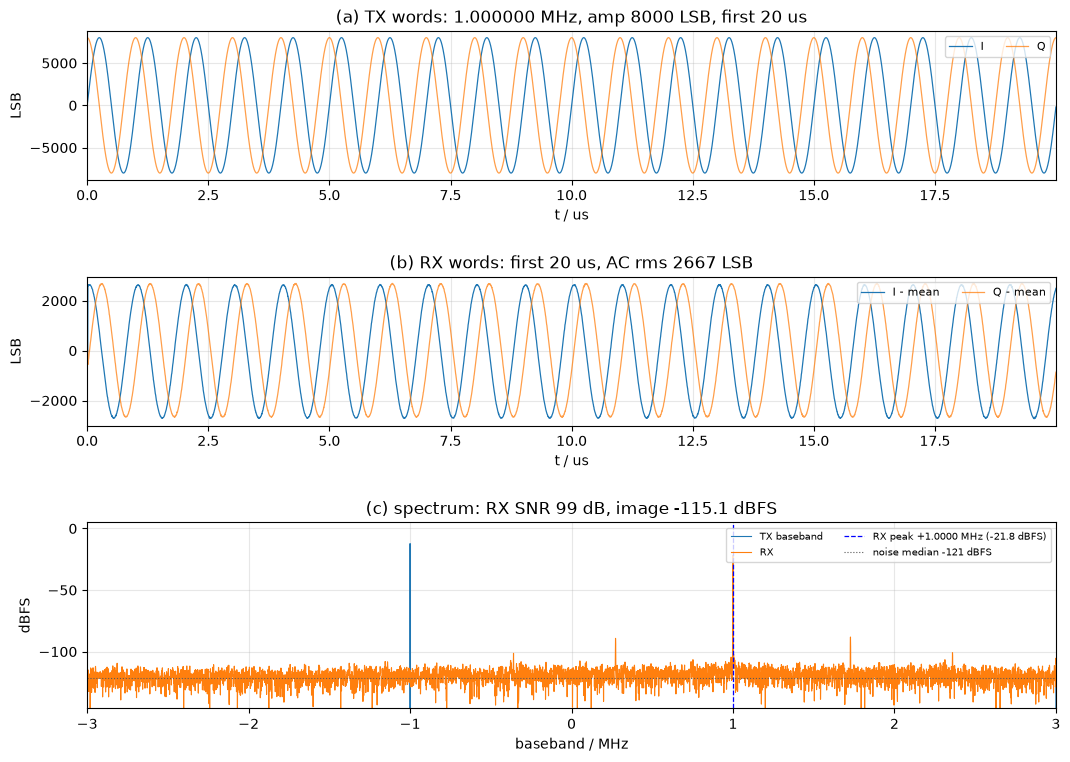

判读：
  (a) TX 在一个 I/Q 平面上转圈，幅度恒定 8000 LSB。
  (b) RX 也转圈，幅度小得多，圆心偏移就是 ADC 直流失调。
  (c) 主峰 +1.0000 MHz -21.8 dBFS，噪底 -121.2 dBFS，SNR 99 dB。
      DC 附近的峰是本振泄漏，不是信号；判读一律绕开 0 Hz。


In [27]:
if n_real >= 1024:
    import matplotlib.pyplot as plt

    def unpack_words(w):
        w = np.asarray(w, dtype=np.uint32)
        i = (w & 0xFFFF).astype(np.uint16).view(np.int16).astype(np.float64)
        q = (w >> 16).astype(np.uint16).view(np.int16).astype(np.float64)
        return i + 1j * q

    TX_IQ = unpack_words(words)
    fig = plt.figure(figsize=(12.5, 8.8))
    gs = fig.add_gridspec(3, 1, height_ratios=[1.0, 1.0, 1.25], hspace=0.6)

    # (a) TX 前 20 us
    ax = fig.add_subplot(gs[0])
    VIEW = min(5120, len(TX_IQ))
    t = np.arange(VIEW) / FS_WORD * 1e6
    ax.plot(t, TX_IQ.real[:VIEW], lw=0.9, label="I")
    ax.plot(t, TX_IQ.imag[:VIEW], lw=0.9, alpha=0.75, label="Q")
    ax.set_xlim(0, t[-1])
    ax.set_xlabel("t / us")
    ax.set_ylabel("LSB")
    ax.set_title("(a) TX words: %.6f MHz, amp %d LSB, first %.0f us"
                 % (F0 / 1e6, AMP, t[-1]))
    ax.legend(loc="upper right", fontsize=8, ncol=2)
    ax.grid(alpha=0.3)

    # (b) RX 前 20 us（去直流）
    ax = fig.add_subplot(gs[1])
    V = min(VIEW, len(x))
    t2 = np.arange(V) / FS_WORD * 1e6
    ax.plot(t2, x.real[:V] - x.real.mean(), lw=0.9, label="I - mean")
    ax.plot(t2, x.imag[:V] - x.imag.mean(), lw=0.9, alpha=0.75, label="Q - mean")
    ax.set_xlim(0, t2[-1])
    ax.set_xlabel("t / us")
    ax.set_ylabel("LSB")
    ax.set_title("(b) RX words: first %.0f us, AC rms %.0f LSB"
                 % (t2[-1], rx_rms))
    ax.legend(loc="upper right", fontsize=8, ncol=2)
    ax.grid(alpha=0.3)

    # (c) 频谱：TX vs RX，±3 MHz
    ax = fig.add_subplot(gs[2])
    f_tx, p_tx = spec_db(TX_IQ)
    mtx = np.abs(f_tx) <= 3.0e6
    ax.plot(f_tx[mtx] / 1e6, p_tx[mtx], lw=0.8, label="TX baseband")
    ax.plot(f / 1e6, pdb, lw=0.8, label="RX")
    ax.axvline(PEAK_HZ / 1e6, color="b", ls="--", lw=0.9,
               label="RX peak %+.4f MHz (%.1f dBFS)" % (PEAK_HZ / 1e6, PEAK_DBFS))
    ax.axhline(noise, color="0.35", ls=":", lw=0.8,
               label="noise median %.0f dBFS" % noise)
    ax.set_xlim(-3, 3)
    ax.set_ylim(max(-170, noise - 25), 5)
    ax.set_xlabel("baseband / MHz")
    ax.set_ylabel("dBFS")
    ax.set_title("(c) spectrum: RX SNR %.0f dB, image %.1f dBFS" % (snr, img))
    ax.legend(loc="upper right", fontsize=7.5, ncol=2)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("判读：")
    print("  (a) TX 在一个 I/Q 平面上转圈，幅度恒定 %d LSB。" % AMP)
    print("  (b) RX 也转圈，幅度小得多，圆心偏移就是 ADC 直流失调。")
    print("  (c) 主峰 %+.4f MHz %.1f dBFS，噪底 %.1f dBFS，SNR %.0f dB。"
          % (PEAK_HZ / 1e6, PEAK_DBFS, noise, snr))
    print("      DC 附近的峰是本振泄漏，不是信号；判读一律绕开 0 Hz。")
else:
    print("没有足够的 RX 数据，跳过作图")


## 10. 收尾：安全停发、汇总、故障树

### 10.1 为什么要"带超时的停发"

`TX.stop()` 最后会写 `DMACR`。如果 MM2S 的 AXI-Lite 已经挂死（例如 PL 时钟被 RFDC 更新打断），这次写可能**永久阻塞**，整个内核就卡死了。所以停发放在守护线程里做，主线程等 3 s 就往下走：数据已经抓到，收尾不能反过来毁掉结果。

### 动手：停发、汇总、释放缓冲区


In [28]:
_halt_done = threading.Event()


def _halt_tx():
    try:
        TX.stop()
    except Exception as e:
        print("  stop() 抛异常：", e)
    finally:
        _halt_done.set()


try:
    threading.Thread(target=_halt_tx, name="halt-tx", daemon=True).start()
    if _halt_done.wait(3.0):
        print("TX 通道已停止（本册只发一次，IOC 后 DMA 本就已停下）。")
    else:
        print("TX 停止请求已发出，但 3 s 内没回来 —— MM2S 的 AXI-Lite 无响应。")
        print("  已抓到的数据不受影响；要恢复请重载 overlay 或复位板卡。")
except NameError:
    print("TX 未创建（第 6 节未成功执行），无需停止。")

_tx_ok = globals().get("tx_ok", None)
_tx_dt = globals().get("tx_dt", float("nan"))
if _tx_ok is not None:
    print("本次突发：%s，从启动到 IOC %.2f ms（帧长 %.3f ms）"
          % ("完成(IOC)" if _tx_ok else "未完成", _tx_dt * 1e3,
             globals().get("FRAME_MS", float("nan"))))

bad = summary("04 单音回环（一发一收）汇总")

# 后面这些量在 RX 失败时可能未定义，统一兜底，保证汇总一定打得出来
_n_real = globals().get("n_real", 0)
_snr = globals().get("snr", float("nan"))
_f0 = globals().get("F0", float("nan"))
_frame_ms = globals().get("FRAME_MS", float("nan"))

print()
if not bad:
    print("链路通：LMK 锁定 → DAC0 tile0 FULL → NCO %.0f MHz → "
          "外部环回 → ADC0 → S2MM。" % NCO_MHZ)
    print("基带 %.6f MHz，TX 帧 %.3f ms，RX 实收 %d 字，SNR %.0f dB。"
          % (_f0 / 1e6, _frame_ms, _n_real, _snr))
    print("射频口应在 %.0f MHz ± %.4f MHz 出峰（NCO ± 基带）。"
          % (NCO_MHZ, _f0 / 1e6))
else:
    print("按上面的『未通过项与处置』逐条排查；先修上游（LMK / RFDC），再看外部环回。")

try:
    buf.freebuffer()
    print("TX 缓冲区已释放；要再测就重跑第 5、6 节。")
except Exception:
    pass


TX 通道已停止（本册只发一次，IOC 后 DMA 本就已停下）。
本次突发：完成(IOC)，从启动到 IOC 0.04 ms（帧长 16.382 ms）

 04 单音回环（一发一收）汇总
  结果    项目                                         实测 / 说明
  ----------------------------------------------------------------------------
  PASS  运行身份是 root                                 uid=0
  PASS  位流 soc.bit 存在                              /home/xilinx/jupyter_notebooks/v106/soc.bit
  PASS  硬件描述 soc.hwh 存在                            /home/xilinx/jupyter_notebooks/v106/soc.hwh
  PASS  LMK 读回可信                                   sane=True
  PASS  LMK PLL2 锁定（RFDC 时钟源）                      R0x183=0x02
  PASS  SYSREF 连续输出（MUX=3）                         R0x139 MUX=3
  PASS  IP 在位 AXI DMA RX/S2MM                      bb/axi_dma_0 @ 0x80000000
  PASS  IP 在位 AXI DMA TX/MM2S                      bb/axi_dma_1 @ 0x80020000
  PASS  IP 在位 usp_rf_data_converter_0              rf_adda_phy/usp_rf_data_converter_0 @ 0x80040000
  FAIL  IP 在位 adc2axis_0                           MISSING @ --
  PASS  xrfdc

### 10.2 故障树（按出现顺序查）

| 症状 | 最可能原因 | 第一动作 |
| --- | --- | --- |
| LMK `sane=False` | SPI 读回窗口不对 | `FORCE_PROGRAM=True` 重跑 §2 |
| `PLL2 LD=0` | SYSREF/时钟脚本没跑 | `sysref_start.py --sysref-div 384` |
| RFDC `is_ready=False` | 非 root / 位流没加载 | 查 `uid`、重载 Overlay |
| DAC `state≠0xF` | tile 启动被打断 | 重跑 §3（先 deinit 再 init） |
| NCO 回读不变 | 事件源没锁存 | 看 §4 的候选列表，检查 SYSREF |
| TX 无 IOC | `RS` 没置上 / 突发没发完 | 读 `DMASR`，复位 DMA |
| RX 无 IOC | S2MM 没启动/基地址错 | 重跑 §7；确认 `adc2axis` 有数据 |
| RX 全是同一个值 | ADC 没数据流 | 查 ADC tile 使能、SYSREF |
| RX 实收远小于整包 | 帧计数没归零 | 先跑 §7.4 的预热抓取 |
| 只有 DC 峰 | 外部环回没接 / 衰减器断 | 用频谱仪直接看 TX SMA |
| 峰偏 ±2% | 字率口径不对 | 确认 `fs_mhz()` 回读 4096 |
| 峰在 −1 MHz | I/Q 方向相反 | 正常，判据已取绝对值 |

### 10.3 参数速查

| 想改什么 | 改哪里 | 连带影响 |
| --- | --- | --- |
| 单音频率 | `TONE_HZ` | 帧长取整、峰位、频偏判据 |
| 输出功率 | `AMP` | 衰减器选型、ADC 饱和 |
| 射频频段 | `NCO_MHZ` | 射频峰位；0 = 零中频 |
| 单次突发长度 | `TX_FRAME_US` | 必须 ≥ 整包接收窗；受 LENGTH 上限 |
| 接收是否整包 | `RX_FULL_FRAME` | False → 只抓 1.024 ms，S2MM 停在包中间 |
| 通道 | `DAC_TILE/BLK`、`ADC_TILE/BLK` | 必须与实际走线一致 |
| 接收长度 | 第 7 节 `REQ_WORDS` | 整包 = `C_FRAME_LEN`；受 24 bit LENGTH 上限 |


## 11. 动手实验：在跑通之后再理解

按顺序做，每次只改一个参数，观察 §8 的指标怎么变。

| # | 改动 | 观察 | 应该理解什么 |
| --- | --- | --- | --- |
| 1 | `TONE_HZ` = 5 MHz | 帧长必须是 256 倍数；峰移到 ±5 MHz | 频率分辨率 $f_s/N$ 与整周期条件 |
| 2 | `TONE_HZ` = 1.0001 MHz | 峰位、频偏、泄漏 | 非整周期 → 频谱泄漏 |
| 3 | `AMP` = 4000 / 16000 | AC RMS、饱和 | dBFS 与 ADC 满量程 |
| 4 | `RX_FULL_FRAME` = False | 每次只抓 1.024 ms，`与整包差` 变成 -3.9 M | 中途停止 vs `tlast` 对齐的差别 |
| 5 | `NCO_MHZ` = 0 | 射频峰移到 1 MHz，DC 泄漏叠在信号上 | 零中频与本振泄漏 |
| 6 | 拔掉衰减器直连 | AC RMS 暴涨、波形削顶 | ADC 饱和 |
| 7 | 不接环回 | 只有 DC + 底噪，SNR FAIL | 判据的含义 |
| 8 | 断开一根同轴 | 与 7 相同 | 排错顺序：先看 TX 口 |

**进阶方向**：双音互调（叠加两个 `tone_words`）、扫频（逐点改 `TONE_HZ` 画幅频响应）、噪声底与衰减量的关系（估链路增益）、用 RX 数据估 EVM（与 TX 理想星座比）。

## 术语对照

| 中文 | English |
| --- | --- |
| 本振 / 数控振荡器 | LO / NCO |
| 复基带 | complex baseband |
| 上变频 / 下变频 | up-conversion / down-conversion |
| 复数转实数 / 实数转复数 | C2R / R2C |
| 插值 / 抽取 | interpolation / decimation |
| 单边带 | single sideband (SSB) |
| 无杂散动态范围 | SFDR |
| 信噪比 | SNR |
| 本振泄漏 | LO leakage |
| 冻结（保持最后码） | frozen / stuck code |
| 描述符链 | scatter-gather (SG) |
